# Statistical Arbitrage with ML Ranking and Markowitz Optimisation

**Pipeline**

1. **Data**: your OHLCV-derived feature panel (one row per stock per day).
2. **Target**: probability that a stock beats the cross-sectional median return over the next *h* days (h = 1, 5, 10).
3. **Feature selection**: the permutation-importance (PI) methods of *Carta et al. (2022), "Statistical arbitrage powered by Explainable Artificial Intelligence", ESWA 206* (**PI best, PI worst, PI running** with an optimised importance threshold), plus three filter methods for comparison.
4. **Models**: Ridge, ElasticNet, Random Forest, XGBoost, RNN, LSTM, ARIMA. Features are chosen on the **train** period, hyperparameters on the **validation** period.
5. **Walk-forward training** over the test period (Jul 2024 – Aug 2026): **rolling**, **expanding** and **jumping** windows (90-day window, quarterly refit).
6. **Ranking**: stocks sorted by predicted probability; long the top *k*, short the bottom *k*.
7. **Portfolio weights**: equal weight, or **Markowitz** mean–variance with expected return proxied by the past *m*-day rolling mean return.
8. **Backtest**: daily rebalancing (or every *h* days), **no transaction costs**.
9. **Comparison**: one consolidated leaderboard and charts across every combination.

**How to run**

1. Set `DATA_PATH` in the configuration cell.
2. Run with `QUICK_RUN = True` first (small grid, finishes quickly) to check the pipeline end to end.
3. Set `QUICK_RUN = False` for the full grid. Every model run is cached in `RESULTS_DIR`, so an interrupted run resumes where it stopped.

Required packages: `numpy pandas scikit-learn scipy matplotlib seaborn xgboost statsmodels torch joblib tqdm`.

## 0. Imports

In [2]:
import os, time, warnings, pickle, json, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy.stats import norm
from scipy.optimize import minimize

import sklearn
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, Ridge, ElasticNet
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from sklearn.covariance import LedoitWolf
from joblib import Parallel, delayed

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kwargs):
        return x

try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

try:
    import torch
    import torch.nn as nn
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False

try:
    from statsmodels.tsa.arima.model import ARIMA
    HAS_SM = True
except ImportError:
    HAS_SM = False

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
print(f"xgboost: {HAS_XGB} | torch: {HAS_TORCH} | statsmodels: {HAS_SM} | sklearn {sklearn.__version__}")

xgboost: True | torch: True | statsmodels: True | sklearn 1.6.1


## 1. Configuration
Every experiment parameter lives here.

In [6]:
# ---------------------------------------------------------------- run mode
QUICK_RUN = False          # True = small grid to test the pipeline; False = full grid

# ---------------------------------------------------------------- data
DATA_PATH = r"C:\Users\khare\JN\features_panel.csv"            # <-- path to your feature panel: .csv / .parquet / .xlsx (one sheet per stock)
DATE_COL, SYMBOL_COL, CLOSE_COL = "Date", "Symbol", "Close"
FEATURE_COLS = None       # None = auto-detect numeric feature columns, or pass an explicit list
NON_FEATURE_COLS = ["Open", "High", "Low", "Close", "Volume"]   # never used as features
LEAK_PATTERNS = ["fwd", "target"]   # any column containing these is dropped (future information)
MAX_MISSING_FRAC = 0.5    # drop features missing in more than 50% of training rows
FEATURE_TRANSFORM = "cs_zscore"     # 'cs_zscore' | 'cs_rank' | 'none' (cross-sectional, per date)
# ---------------------------------------------------------------- sample split
#   Burn-in     2018                 features warm up (e.g. 12-month momentum); never used for training
#   Train       2019 -> Dec 2022     fit models, choose features (PI feature selection)
#   Validation  Jan 2023 -> Jun 2024 choose each model's hyper-parameters
#   Test        Jul 2024 -> Aug 2026 final evaluation only, never used for any choice
TRAIN_START = "2019-01-01"
VAL_START   = "2023-01-01"
TEST_START  = "2024-07-01"
TEST_END    = "2026-08-31"

# ---------------------------------------------------------------- experiment grid
MODELS = ["Ridge", "ElasticNet", "RandomForest", "XGBoost", "RNN", "LSTM", "ARIMA"]
FS_METHODS = ["all", "PI_best", "PI_worst", "PI_running"]
TRAIN_METHODS = ["expanding"]
HORIZONS = [20]                                   # prediction horizon (trading days)
PORTFOLIOS = {"L5S5": (5, 5)}   # (n_long, n_short)
WEIGHTINGS = ["markowitz"]
MU_LOOKBACKS = [20]   # m: expected-return proxy = past m-day rolling mean return (Markowitz)
REBALANCE = "daily"       # 'daily' = rebalance whenever predictions change; 'horizon' = every h days
EXECUTION_LAG = 0         # 0 = trade at close of signal day t; 1 = trade one day later

# ---------------------------------------------------------------- training windows
TRAIN_WINDOW = 180        # trading days in the training window (rolling / jumping)
REFIT_EVERY = 63          # refit frequency for rolling / expanding (63 ≈ quarterly)
                          # jumping refits every TRAIN_WINDOW days -> non-overlapping windows
EXPANDING_MAX_DAYS = None # cap on the expanding window (None = all history)
TASK = "classification"   # 'classification' (P(beat median)) or 'regression' (excess return -> probability)

# ---------------------------------------------------------------- hyperparameter tuning (validation period only)
TUNE = True
TUNE_FOLDS = None         # folds inside the validation period (None = all that fit, ~1 per quarter)

# ---------------------------------------------------------------- feature selection
FS_VALID_FOLDS = 6        # folds inside the train period for permutation importance (spread evenly; None = all)
FS_LOSS = "logloss"       # 'logloss' | 'brier' | 'mean_return'  (loss used by the PI methods)
N_PERMUTATIONS = 10       # paper uses 100; raise if you have time
PI_THRESHOLDS = np.round(np.arange(0.0, -0.02501, -0.0001), 4)   # paper: [0, -0.025] step 0.0001
PI_K_LIST = [1, 3, 5, 7, 10, 15, 20, 25, 30]  # max number of features removed (paper: K = 1, 3, 5, 7)
PI_PROXY_FOR_NN = "XGBoost"   # PI for RNN/LSTM is computed with this tabular model
PI_TRADE_K = 5            # k used by the 'mean_return' loss (top-k minus bottom-k)
CORR_THRESHOLD = 0.90     # corr_filter: max |correlation| between kept features
MI_KEEP_FRAC = 0.5        # mutual_info: fraction of features kept
IC_TSTAT_MIN = 2.0        # ic_tstat: keep features with |t-stat of daily rank IC| >= this
MIN_FEATURES = 5          # every method keeps at least this many features
FS_SAMPLE_ROWS = 60_000   # row sample for correlation / MI computations

# ---------------------------------------------------------------- neural networks
SEQ_LEN = 20              # days of history fed to RNN / LSTM
NN_BATCH = 512
NN_MAX_TRAIN_ROWS = 150_000

# ---------------------------------------------------------------- ARIMA
ARIMA_ORDERS = [(1, 0, 0), (0, 0, 1), (1, 0, 1), (2, 0, 0)]   # chosen per stock by AIC
ARIMA_APPLY_LEN = 250     # history length used when forecasting with fitted parameters

# ---------------------------------------------------------------- Markowitz
COV_LOOKBACK = 60         # days for the (Ledoit-Wolf) covariance matrix
RISK_AVERSION = 10.0      # lambda in  max  w'mu - lambda/2 w'Sigma w
W_MAX = 0.40              # max |weight| per stock within a leg

# ---------------------------------------------------------------- misc
RESULTS_DIR = Path("results_split_copy")   # new folder: caches from the old split are not reused
SEED = 42
N_JOBS = os.cpu_count() or 1

# ---------------------------------------------------------------- quick-run overrides
if QUICK_RUN:
    MODELS = ["Ridge", "XGBoost", "LSTM", "ARIMA"]
    FS_METHODS = ["all", "corr_filter", "PI_running"]
    TRAIN_METHODS = ["rolling", "expanding"]
    HORIZONS = [1, 5]
    MU_LOOKBACKS = [20]
    TUNE_FOLDS = FS_VALID_FOLDS = 2
    N_PERMUTATIONS = 3
    PI_THRESHOLDS = np.round(np.arange(0.0, -0.02501, -0.0025), 4)
    ARIMA_ORDERS = [(1, 0, 0), (0, 0, 1)]
    RESULTS_DIR = Path("results_split_quick")

# drop models whose package is missing
_missing = {"XGBoost": HAS_XGB, "RNN": HAS_TORCH, "LSTM": HAS_TORCH, "ARIMA": HAS_SM}
for _m, _ok in _missing.items():
    if _m in MODELS and not _ok:
        print(f"WARNING: {_m} removed (package not installed)")
        MODELS.remove(_m)
if PI_PROXY_FOR_NN == "XGBoost" and not HAS_XGB:
    PI_PROXY_FOR_NN = "RandomForest"

CLS = TASK == "classification"
for sub in ["tuning", "fs", "preds", "figures"]:
    (RESULTS_DIR / sub).mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)
if HAS_TORCH:
    torch.manual_seed(SEED)
    torch.set_num_threads(N_JOBS)
print("Models:", MODELS)
print("FS methods:", FS_METHODS)
print("Train methods:", TRAIN_METHODS, "| Horizons:", HORIZONS)

Models: ['Ridge', 'ElasticNet', 'RandomForest', 'XGBoost', 'RNN', 'LSTM', 'ARIMA']
FS methods: ['all', 'PI_best', 'PI_worst', 'PI_running']
Train methods: ['expanding'] | Horizons: [20]


## 2. Data
Load your feature panel. Expected layout: one row per (Date, Symbol) with at least `Date`, `Symbol`, `Close` and the feature columns
(for example `features_panel.csv` from `build_features.py`). An `.xlsx` with one sheet per stock also works; the sheet name becomes the symbol.

No data is generated here: set `DATA_PATH` above.

In [7]:
def load_panel(path):
    p = Path(path)
    if p.suffix.lower() in (".parquet", ".pq"):
        d = pd.read_parquet(p)
    elif p.suffix.lower() == ".csv":
        d = pd.read_csv(p)
    elif p.suffix.lower() in (".xlsx", ".xls"):
        sheets = pd.read_excel(p, sheet_name=None)
        d = pd.concat([s.assign(**{SYMBOL_COL: name}) for name, s in sheets.items()], ignore_index=True)
    else:
        raise ValueError(f"Unsupported file type: {p.suffix}")
    return d

assert DATA_PATH, "Set DATA_PATH in the configuration cell to your feature panel file."
raw = load_panel(DATA_PATH)
print(raw.shape)
raw.head()

(505146, 67)


,Date,Open,High,Low,Close,Volume,VWAP,Symbol,r_b,bench_mom_60d,...,bench_drawdown_252d,bench_fwd_ret,rank_mom_20d,rank_mom_60d,rank_rel_mom_60d,rank_vol_20d,rank_resid_ret_60d,rank_log_traded_value_med_20d,target_excess_ret_20d,target_outperform
0,2018-01-01,1281.896484,1282.804321,1261.968994,1270.684448,4.925800e+04,NaN,ABB IS Equity,NaN,NaN,...,NaN,-0.003827,NaN,NaN,NaN,NaN,NaN,NaN,0.151113,1.0
1,2018-01-01,184.500001,189.300004,184.000001,186.399995,2.837824e+06,NaN,ABCAP IS Equity,NaN,NaN,...,NaN,-0.003827,NaN,NaN,NaN,NaN,NaN,NaN,-0.084156,0.0
2,2018-01-01,1426.750000,1446.000000,1410.000000,1417.050049,4.598430e+05,NaN,ABREL IS Equity,NaN,NaN,...,NaN,-0.003827,NaN,NaN,NaN,NaN,NaN,NaN,-0.009899,0.0
3,2018-01-01,271.100006,273.100006,264.350006,268.049988,1.408955e+06,NaN,ACEM IS Equity,NaN,NaN,...,NaN,-0.003827,NaN,NaN,NaN,NaN,NaN,NaN,-0.020609,0.0
4,2018-01-01,8.320000,9.040000,8.180000,8.520000,1.718442e+08,NaN,ADANI IS Equity,NaN,NaN,...,NaN,-0.003827,NaN,NaN,NaN,NaN,NaN,NaN,-0.117066,0.0


## 3. Data preparation
* Cleans and sorts the panel and detects feature columns (anything containing `fwd` / `target` is excluded to prevent leakage).
* Builds forward returns and labels for every horizon *h*: **y = 1 if the stock's h-day forward return beats the cross-sectional median that day**.
* Applies a per-date cross-sectional transform to stock-specific features (market-wide features, identical across stocks on a date, are kept raw).
* Builds the arrays used by the training engine.

In [8]:
df = raw.rename(columns={DATE_COL: "Date", SYMBOL_COL: "Symbol", CLOSE_COL: "Close"}).copy()
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Close"] = pd.to_numeric(df["Close"], errors="coerce")
df = df.dropna(subset=["Date", "Symbol", "Close"])
df = df[df["Close"] > 0].drop_duplicates(["Symbol", "Date"]).sort_values(["Symbol", "Date"]).reset_index(drop=True)
TRAIN_START_TS, VAL_START_TS = pd.Timestamp(TRAIN_START), pd.Timestamp(VAL_START)
TEST_START_TS, TEST_END_TS = pd.Timestamp(TEST_START), pd.Timestamp(TEST_END)

# ---- feature columns
if FEATURE_COLS is None:
    FEATURE_COLS = [c for c in df.columns
                    if c not in ["Date", "Symbol"] + NON_FEATURE_COLS
                    and pd.api.types.is_numeric_dtype(df[c])
                    and not any(p in c.lower() for p in LEAK_PATTERNS)]
_train_rows = (df["Date"] >= TRAIN_START_TS) & (df["Date"] < VAL_START_TS)
_miss = df.loc[_train_rows, FEATURE_COLS].isna().mean()
_dropped = [c for c in FEATURE_COLS if _miss[c] > MAX_MISSING_FRAC]
FEATURE_COLS = [c for c in FEATURE_COLS if c not in _dropped]
if _dropped:
    print("Dropped (too many missing):", _dropped)
print(f"{len(FEATURE_COLS)} features:", FEATURE_COLS)

# ---- wide price matrix -> returns aligned on a common calendar
CLOSE_W = df.pivot(index="Date", columns="Symbol", values="Close").sort_index()
DATES = CLOSE_W.index.values
SYMS = CLOSE_W.columns.values
N_DATES, N_SYMS = len(DATES), len(SYMS)
RET_W = (CLOSE_W / CLOSE_W.shift(1) - 1)                               # return realised on day t (known at t)
NEXT_W = CLOSE_W.shift(-1 - EXECUTION_LAG) / CLOSE_W.shift(-EXECUTION_LAG) - 1   # return earned after trading on t
RD = RET_W.values.astype(np.float64)
RN = NEXT_W.values.astype(np.float64)

key = pd.MultiIndex.from_frame(df[["Date", "Symbol"]])
for h in HORIZONS:
    fwd = (CLOSE_W.shift(-h) / CLOSE_W - 1)
    med = fwd.median(axis=1)
    exc = fwd.sub(med, axis=0)
    df[f"_fwd_{h}"] = fwd.stack().reindex(key).values
    df[f"_exc_{h}"] = exc.stack().reindex(key).values
    df[f"_y_{h}"] = np.where(np.isnan(df[f"_exc_{h}"]), np.nan, (df[f"_exc_{h}"] > 0).astype(float))

# ---- cross-sectional feature transform
Xraw = df[FEATURE_COLS].astype(float)
cs_std = Xraw.groupby(df["Date"]).std()
MARKET_FEATURES = [c for c in FEATURE_COLS if (cs_std[c].fillna(0) < 1e-12).mean() > 0.8]
CS_FEATURES = [c for c in FEATURE_COLS if c not in MARKET_FEATURES]
Xt = Xraw.copy()
if FEATURE_TRANSFORM == "cs_zscore" and CS_FEATURES:
    g = Xraw[CS_FEATURES].groupby(df["Date"])
    Xt[CS_FEATURES] = ((Xraw[CS_FEATURES] - g.transform("mean")) / g.transform("std")).clip(-5, 5).fillna(0.0)
elif FEATURE_TRANSFORM == "cs_rank" and CS_FEATURES:
    Xt[CS_FEATURES] = (Xraw[CS_FEATURES].groupby(df["Date"]).rank(pct=True) - 0.5).fillna(0.0)
print("Market-wide features (kept raw):", MARKET_FEATURES)

# ---- engine arrays (panel sorted by Symbol, Date)
PANEL_X = Xt.values.astype(np.float32)
DPOS = np.searchsorted(DATES, df["Date"].values)
SID = np.searchsorted(SYMS, df["Symbol"].values)
POS_IN_SYM = df.groupby("Symbol").cumcount().values
FWD = {h: df[f"_fwd_{h}"].values for h in HORIZONS}
EXC = {h: df[f"_exc_{h}"].values for h in HORIZONS}
Y = {h: df[f"_y_{h}"].values for h in HORIZONS}
ALL_COLS = np.arange(len(FEATURE_COLS))
FNAMES = np.array(FEATURE_COLS)

_order = np.argsort(DPOS, kind="stable")
_starts = np.r_[0, np.cumsum(np.bincount(DPOS, minlength=N_DATES))]

def rows_between(a, b):
    """Panel row indices for date positions a..b (inclusive)."""
    a, b = max(int(a), 0), min(int(b), N_DATES - 1)
    if b < a:
        return np.array([], dtype=int)
    return np.sort(_order[_starts[a]:_starts[b + 1]])

def labeled(rows, h):
    return rows[~np.isnan(Y[h][rows])]

TRAIN0 = int(np.searchsorted(DATES, np.datetime64(TRAIN_START_TS)))            # first train date
V0 = int(np.searchsorted(DATES, np.datetime64(VAL_START_TS)))                   # first validation date
T0 = int(np.searchsorted(DATES, np.datetime64(TEST_START_TS)))                  # first test date
TEND = int(np.searchsorted(DATES, np.datetime64(TEST_END_TS), side="right")) - 1  # last test date
assert 0 < TRAIN0 < V0 < T0 <= TEND < N_DATES, "Check TRAIN_START / VAL_START / TEST_START / TEST_END against the data range"
print(f"{N_SYMS} stocks | {N_DATES} dates ({pd.Timestamp(DATES[0]).date()} -> {pd.Timestamp(DATES[-1]).date()})")
_d = lambda p: pd.Timestamp(DATES[p]).date()
print(f"Burn-in    : {_d(0)} -> {_d(TRAIN0 - 1)}  ({TRAIN0} dates, features only)")
print(f"Train      : {_d(TRAIN0)} -> {_d(V0 - 1)}  ({V0 - TRAIN0} dates)")
print(f"Validation : {_d(V0)} -> {_d(T0 - 1)}  ({T0 - V0} dates)")
print(f"Test       : {_d(T0)} -> {_d(TEND)}  ({TEND - T0 + 1} dates)")

56 features: ['VWAP', 'r_b', 'bench_mom_60d', 'bench_mom_120d', 'bench_vol_60d', 'ret_1d', 'ret_5d', 'mom_20d', 'mom_60d', 'mom_120d', 'mom_252d', 'rel_mom_20d', 'rel_mom_60d', 'rel_mom_120d', 'vol_20d', 'vol_60d', 'downside_vol_20d', 'vol_ratio_20_60', 'parkinson_vol_20d', 'vol_adj_mom_60d', 'mom_accel_20d', 'dist_high_20d', 'dist_high_60d', 'dist_low_60d', 'dist_ma20', 'dist_ma50', 'dist_ma200', 'ma50_ma200_ratio', 'ma50_slope_20d', 'trend_consistency_60d', 'log_volume', 'log_traded_value_med_20d', 'rel_volume_20d', 'volume_trend_20_60', 'price_volume_interaction', 'intraday_return', 'intraday_range', 'candle_body', 'overnight_gap_mean_20d', 'gap_vol_20d', 'clv_mean_20d', 'beta_60d', 'beta_120d', 'corr_60d', 'rel_vol_60d', 'resid_ret_60d', 'bench_ret_20d', 'bench_dist_ma200', 'bench_vol_20d', 'bench_drawdown_252d', 'rank_mom_20d', 'rank_mom_60d', 'rank_rel_mom_60d', 'rank_vol_20d', 'rank_resid_ret_60d', 'rank_log_traded_value_med_20d']
Market-wide features (kept raw): ['r_b', 'bench_

### 3.1 Data overview

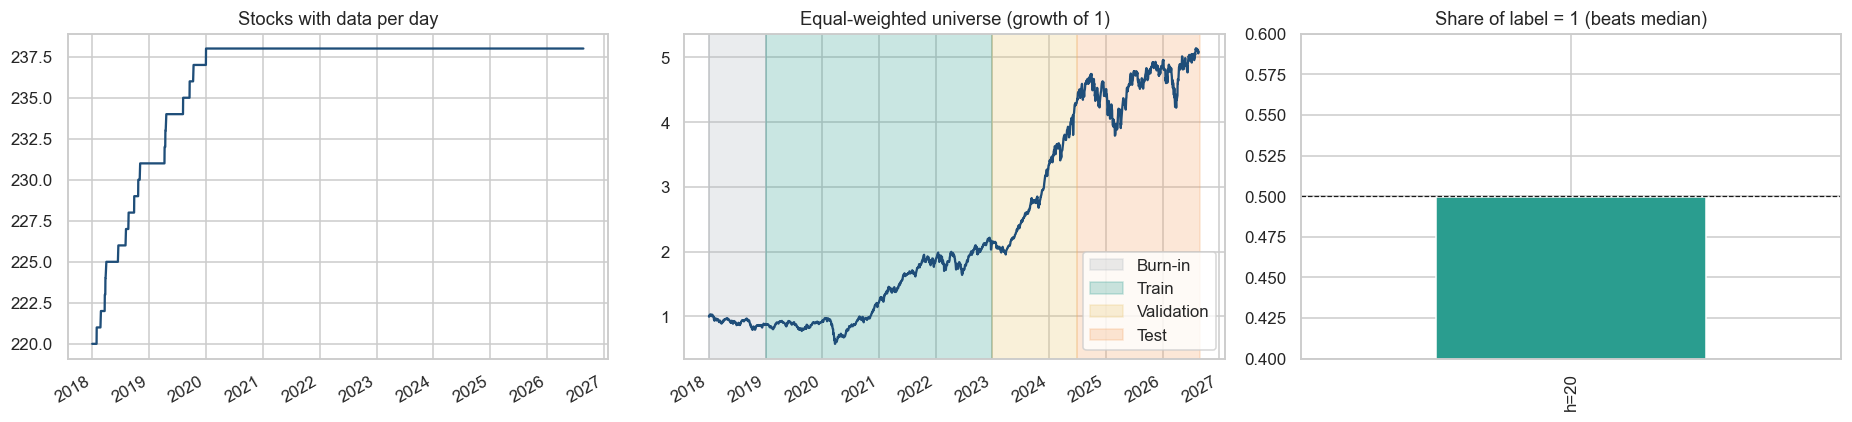

In [9]:
FIG_DIR = RESULTS_DIR / "figures"
def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

ew_ret = RET_W.mean(axis=1).fillna(0)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
CLOSE_W.notna().sum(axis=1).plot(ax=axes[0], color="#1f4e79")
axes[0].set_title("Stocks with data per day"); axes[0].set_xlabel("")
(1 + ew_ret).cumprod().plot(ax=axes[1], color="#1f4e79")
for (a, b, c, lab) in [(DATES[0], TRAIN_START_TS, "#adb5bd", "Burn-in"), (TRAIN_START_TS, VAL_START_TS, "#2a9d8f", "Train"),
                       (VAL_START_TS, TEST_START_TS, "#e9c46a", "Validation"), (TEST_START_TS, TEST_END_TS, "#f4a261", "Test")]:
    axes[1].axvspan(pd.Timestamp(a), pd.Timestamp(b), color=c, alpha=0.25, label=lab)
axes[1].set_title("Equal-weighted universe (growth of 1)"); axes[1].legend(); axes[1].set_xlabel("")
pd.Series({f"h={h}": np.nanmean(Y[h]) for h in HORIZONS}).plot.bar(ax=axes[2], color="#2a9d8f")
axes[2].axhline(0.5, color="k", lw=0.8, ls="--"); axes[2].set_ylim(0.4, 0.6)
axes[2].set_title("Share of label = 1 (beats median)")
plt.tight_layout(); savefig("data_overview"); plt.show()

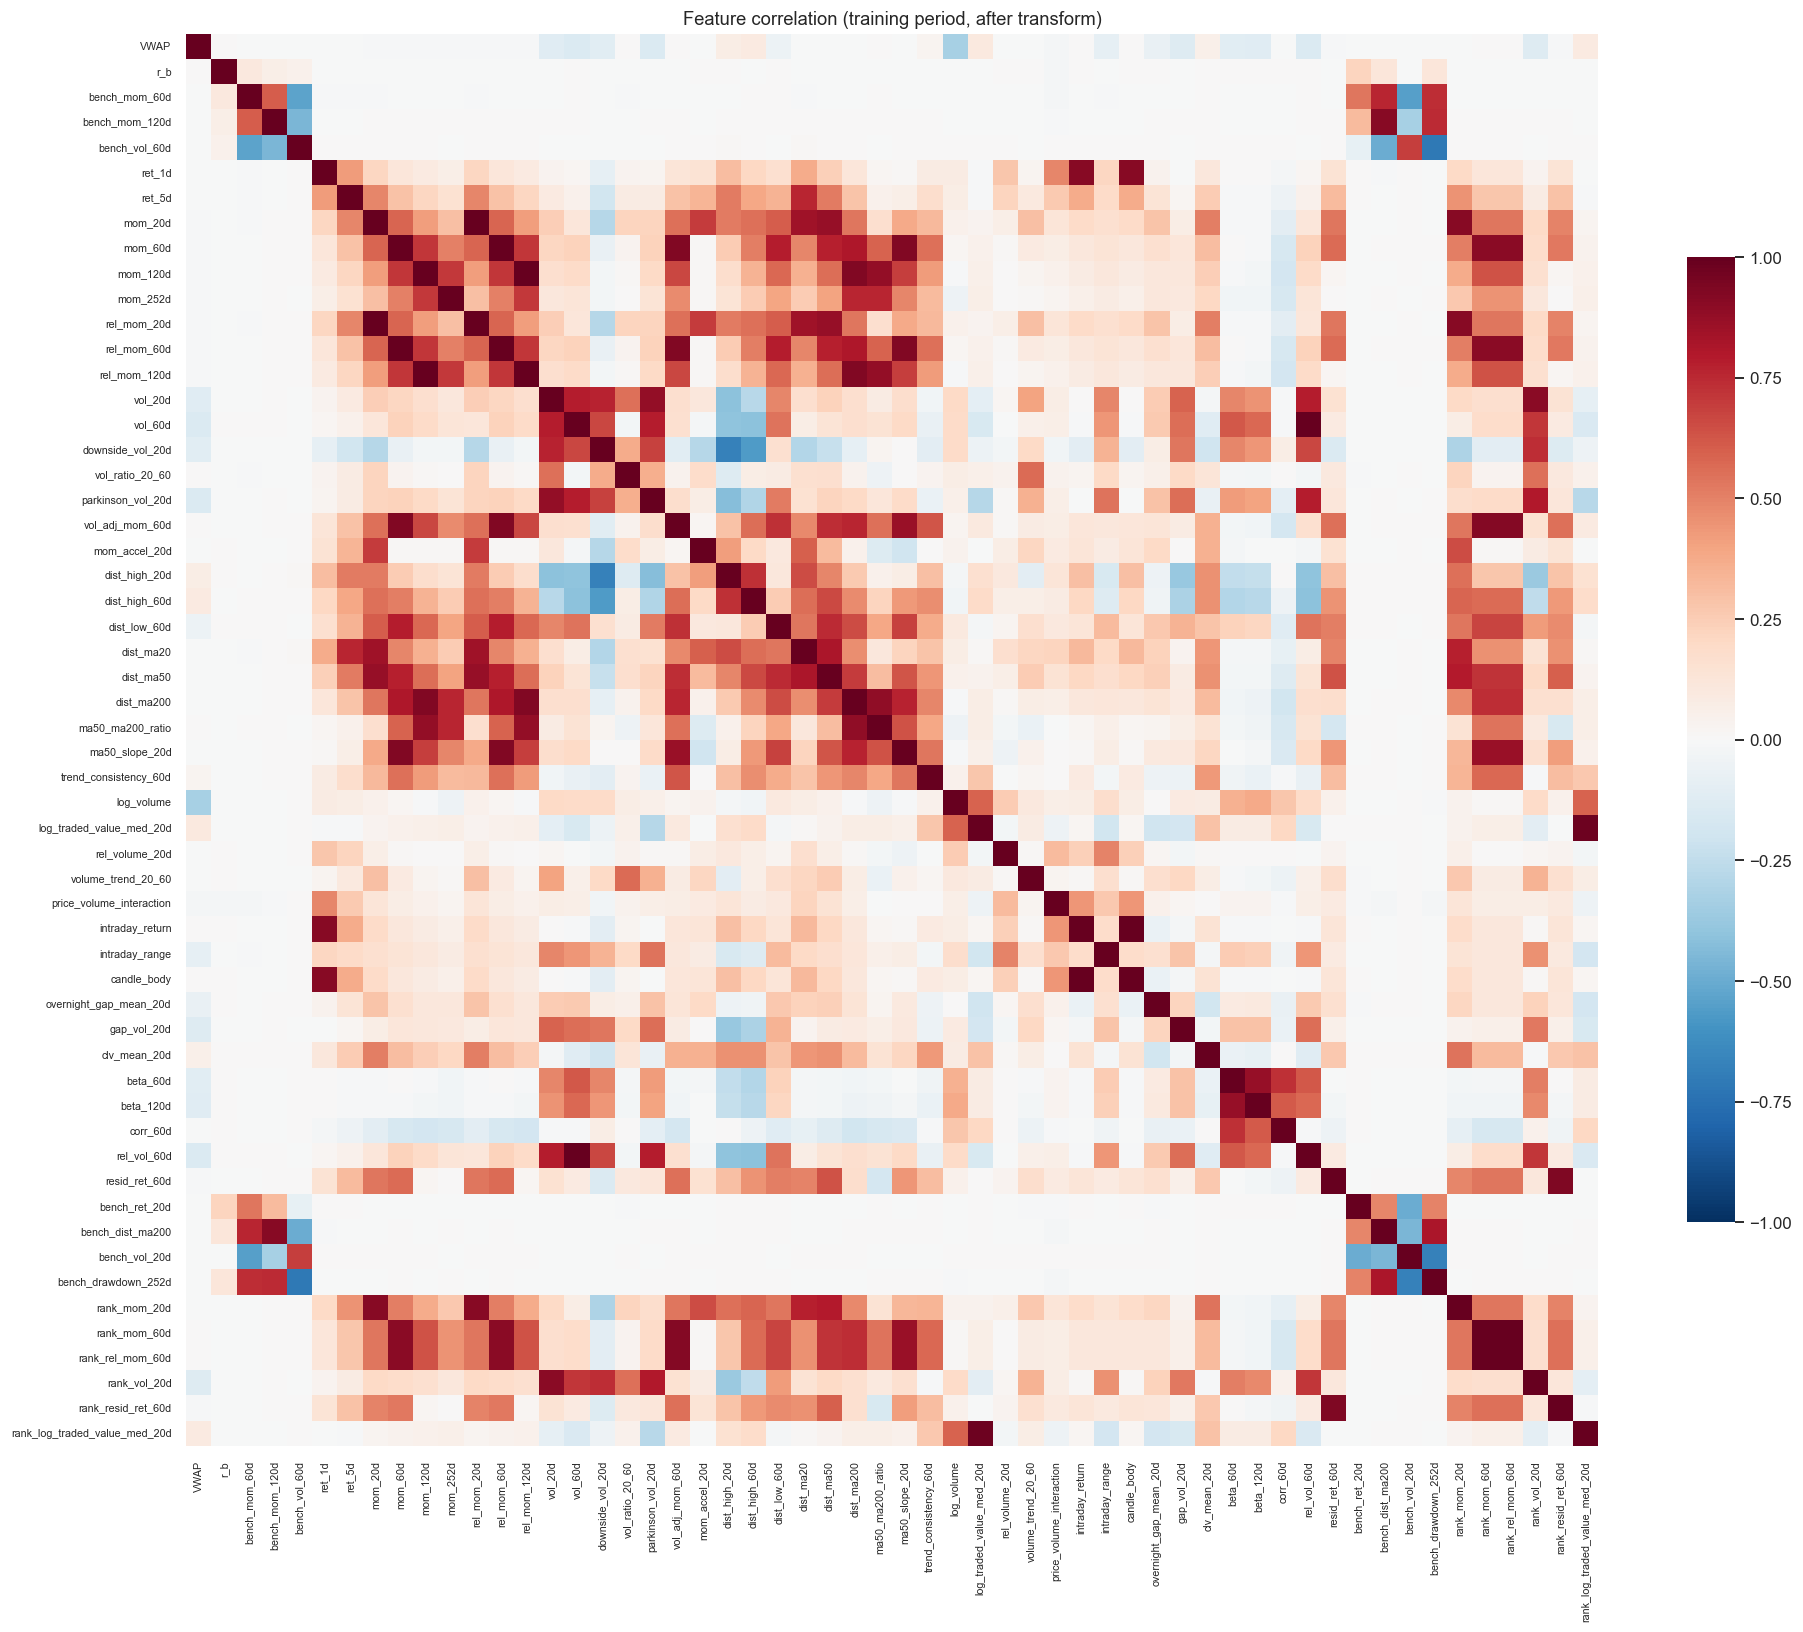

In [10]:
_tr_sample = rows_between(TRAIN0, V0 - 1)
_tr_sample = np.random.default_rng(SEED).choice(_tr_sample, min(len(_tr_sample), FS_SAMPLE_ROWS), replace=False)
corr_all = pd.DataFrame(PANEL_X[_tr_sample], columns=FEATURE_COLS).corr()
plt.figure(figsize=(min(1 + 0.32 * len(FEATURE_COLS), 18), min(1 + 0.3 * len(FEATURE_COLS), 16)))
sns.heatmap(corr_all, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.6},
            xticklabels=True, yticklabels=True)
plt.title("Feature correlation (training period, after transform)")
plt.xticks(fontsize=7); plt.yticks(fontsize=7)
plt.tight_layout(); savefig("feature_correlation"); plt.show()

## 4. Utilities: scoring and walk-forward windows
* **Daily rank IC**: Spearman correlation, each day, between predicted probability and realised forward return. It is the main ranking-quality score.
* **Training range**: to predict on date position *P*, a label at date *p* is usable only if its forward return is complete by *P*, so *p ≤ P − h*. This purges overlapping labels. Training rows never start before `TRAIN_START` (the 2018 burn-in is excluded).
* **Folds never cross period boundaries**: feature-selection folds lie inside the train period and their labels end before Jan 2023; tuning folds lie inside the validation period and their labels end before Jul 2024.
  * **rolling**: the last `TRAIN_WINDOW` days, refit every `REFIT_EVERY` days.
  * **expanding**: all history, refit every `REFIT_EVERY` days.
  * **jumping**: the last `TRAIN_WINDOW` days, refit every `TRAIN_WINDOW` days (non-overlapping windows).

In [11]:
def daily_ic(dpos, pred, fwd):
    t = pd.DataFrame({"d": dpos, "p": pred, "f": fwd}).dropna()
    if t.empty:
        return pd.Series(dtype=float)
    t["p"] = t.groupby("d")["p"].rank()
    t["f"] = t.groupby("d")["f"].rank()
    t["p"] -= t.groupby("d")["p"].transform("mean")
    t["f"] -= t.groupby("d")["f"].transform("mean")
    s = t.assign(xy=t.p * t.f, xx=t.p ** 2, yy=t.f ** 2).groupby("d")[["xy", "xx", "yy"]].sum()
    ic = s.xy / np.sqrt(s.xx * s.yy)
    return ic.replace([np.inf, -np.inf], np.nan).dropna()

def topk_spread(dpos, pred, fwd, k=PI_TRADE_K):
    """Mean (top-k minus bottom-k) forward return per day."""
    t = pd.DataFrame({"d": dpos, "p": pred, "f": fwd}).dropna()
    t["r"] = t.groupby("d")["p"].rank(ascending=False, method="first")
    t["n"] = t.groupby("d")["p"].transform("size")
    top = t[t.r <= k].groupby("d")["f"].mean()
    bot = t[t.r > t.n - k].groupby("d")["f"].mean()
    return (top - bot).mean()

def train_range(P, method, h):
    end = P - h
    if method == "expanding":
        start = TRAIN0 if EXPANDING_MAX_DAYS is None else end - EXPANDING_MAX_DAYS + 1
    else:
        start = end - TRAIN_WINDOW + 1
    return max(start, TRAIN0), end

def refit_schedule(method):
    step = TRAIN_WINDOW if method == "jumping" else REFIT_EVERY
    return [(P, min(P + step, TEND + 1) - 1) for P in range(T0, TEND + 1, step)]

def make_folds(h, n_folds, period, val_len=REFIT_EVERY):
    """Walk-forward (train window, evaluation block) folds whose evaluation blocks lie inside one period.
    period = 'train'      -> blocks in 2019-2022, labels complete before VAL_START   (feature selection)
    period = 'validation' -> blocks in Jan 2023-Jun 2024, labels complete before TEST_START (tuning)
    Each fold trains on the TRAIN_WINDOW days before its block (never before TRAIN_START)."""
    if period == "train":
        lo, hi = TRAIN0 + TRAIN_WINDOW + h, V0 - 1
    else:
        lo, hi = V0, T0 - 1
    blocks = []
    P = lo
    while P + val_len - 1 + h <= hi:                     # label of last block day must be known by hi
        blocks.append(P)
        P += val_len
    if P + h <= hi:                                      # shorter final block
        blocks.append(P)
    folds = []
    for Pv in blocks:
        a, b = train_range(Pv, "rolling", h)
        if b - a + 1 < TRAIN_WINDOW // 2:
            continue
        tr = labeled(rows_between(a, b), h)
        va = labeled(rows_between(Pv, min(Pv + val_len - 1, hi - h)), h)
        if len(tr) > 100 and len(va) > 100:
            folds.append((tr, va))
    if not folds:
        raise ValueError(f"No folds fit in the {period} period; reduce TRAIN_WINDOW or REFIT_EVERY.")
    if n_folds is not None and n_folds < len(folds):     # spread evenly across the period
        idx = np.unique(np.round(np.linspace(0, len(folds) - 1, n_folds)).astype(int))
        folds = [folds[i] for i in idx]
    return folds

def cache_get(path):
    if Path(path).exists():
        with open(path, "rb") as f:
            return pickle.load(f)
    return None

def cache_put(path, obj):
    with open(path, "wb") as f:
        pickle.dump(obj, f)

## 5. Models
Every model outputs **P(stock beats the cross-sectional median over the next h days)**, which is used for the cross-sectional ranking.

| Model | Classification mode (default) | Regression mode |
|---|---|---|
| Ridge | L2-penalised logistic regression | Ridge regression on excess return; probability = Φ(prediction / residual σ) |
| ElasticNet | Elastic-net logistic regression | ElasticNet regression on excess return |
| RandomForest / XGBoost | Classifier | Regressor |
| RNN / LSTM | Sequence of the last `SEQ_LEN` days of features, sigmoid output | Linear output |
| ARIMA | Per-stock ARIMA on daily returns (order chosen by AIC). Probability = Φ((forecast − cross-sectional median forecast) / forecast s.e.). Uses no features. | same |

In [12]:
_SK_NEW = tuple(int(x) for x in sklearn.__version__.split(".")[:2]) >= (1, 8)

def make_logreg(C, l1_ratio):
    solver = "lbfgs" if l1_ratio == 0 else "saga"
    if _SK_NEW:
        return LogisticRegression(C=C, l1_ratio=l1_ratio, solver=solver, max_iter=500, tol=1e-3)
    penalty = "l2" if l1_ratio == 0 else "elasticnet"
    return LogisticRegression(C=C, penalty=penalty, l1_ratio=(l1_ratio if l1_ratio else None),
                              solver=solver, max_iter=500, tol=1e-3)

class TabularModel:
    def __init__(self, name, params):
        self.name, self.params = name, params

    def _estimator(self):
        p = self.params
        if self.name == "Ridge":
            return make_logreg(p["C"], 0.0) if CLS else Ridge(alpha=p["alpha"])
        if self.name == "ElasticNet":
            return make_logreg(p["C"], p["l1_ratio"]) if CLS else ElasticNet(alpha=p["alpha"], l1_ratio=p["l1_ratio"], max_iter=5000)
        if self.name == "RandomForest":
            kw = dict(n_estimators=p["n_estimators"], max_depth=p["max_depth"], min_samples_leaf=p["min_samples_leaf"],
                      max_features=p["max_features"], n_jobs=N_JOBS, random_state=SEED)
            return RandomForestClassifier(**kw) if CLS else RandomForestRegressor(**kw)
        if self.name == "XGBoost":
            kw = dict(n_estimators=p["n_estimators"], max_depth=p["max_depth"], learning_rate=p["learning_rate"],
                      subsample=p["subsample"], colsample_bytree=p["colsample_bytree"], tree_method="hist",
                      n_jobs=N_JOBS, random_state=SEED, verbosity=0)
            return xgb.XGBClassifier(eval_metric="logloss", **kw) if CLS else xgb.XGBRegressor(**kw)
        raise ValueError(self.name)

    def fit(self, rows, cols, h):
        X = PANEL_X[rows][:, cols]
        y = Y[h][rows] if CLS else EXC[h][rows]
        self.pipe = make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), StandardScaler(), self._estimator())
        self.pipe.fit(X, y)
        if not CLS:
            self.sigma = float(np.std(y - self.pipe.predict(X))) + 1e-12
        return self

    def predict_X(self, X):
        if CLS:
            return self.pipe.predict_proba(X)[:, 1]
        return norm.cdf(self.pipe.predict(X) / self.sigma)

    def predict_proba(self, rows, cols):
        return self.predict_X(PANEL_X[rows][:, cols])

if HAS_TORCH:
    class SeqNet(nn.Module):
        def __init__(self, n_in, hidden, layers, dropout, cell):
            super().__init__()
            rnn_cls = nn.LSTM if cell == "LSTM" else nn.RNN
            self.rnn = rnn_cls(n_in, hidden, num_layers=layers, batch_first=True,
                               dropout=dropout if layers > 1 else 0.0)
            self.head = nn.Linear(hidden, 1)

        def forward(self, x):
            out, _ = self.rnn(x)
            return self.head(out[:, -1]).squeeze(-1)

class SeqModel:
    """RNN / LSTM over the last SEQ_LEN days of each stock's features (sequences built on the fly)."""
    def __init__(self, cell, params):
        self.cell, self.params = cell, params

    def _seq_idx(self, rows):
        offs = np.arange(SEQ_LEN - 1, -1, -1)
        return rows[:, None] - np.minimum(offs[None, :], POS_IN_SYM[rows][:, None])

    def _batch(self, rows, cols):
        x = PANEL_X[self._seq_idx(rows)][:, :, cols]
        x = (x - self.mu) / self.sd
        return torch.from_numpy(np.nan_to_num(x, nan=0.0).astype(np.float32))

    def fit(self, rows, cols, h):
        p = self.params
        rng = np.random.default_rng(SEED)
        if len(rows) > NN_MAX_TRAIN_ROWS:
            rows = np.sort(rng.choice(rows, NN_MAX_TRAIN_ROWS, replace=False))
        Xtr = PANEL_X[rows][:, cols].astype(np.float64)
        self.mu = np.nan_to_num(np.nanmean(Xtr, axis=0)).astype(np.float32)
        self.sd = (np.nan_to_num(np.nanstd(Xtr, axis=0)) + 1e-6).astype(np.float32)
        y = Y[h][rows] if CLS else EXC[h][rows]
        if not CLS:
            self.ysd = float(np.std(y)) + 1e-12
            y = y / self.ysd
        y = torch.tensor(y, dtype=torch.float32)
        torch.manual_seed(SEED)
        self.net = SeqNet(len(cols), p["hidden"], p["layers"], p["dropout"], self.cell)
        opt = torch.optim.Adam(self.net.parameters(), lr=p["lr"], weight_decay=1e-5)
        loss_fn = nn.BCEWithLogitsLoss() if CLS else nn.MSELoss()
        self.net.train()
        for _ in range(p["epochs"]):
            perm = rng.permutation(len(rows))
            for i in range(0, len(rows), NN_BATCH):
                b = perm[i:i + NN_BATCH]
                opt.zero_grad()
                loss = loss_fn(self.net(self._batch(rows[b], cols)), y[b])
                loss.backward()
                nn.utils.clip_grad_norm_(self.net.parameters(), 1.0)
                opt.step()
        if not CLS:
            self.sigma = 1.0
        return self

    def predict_proba(self, rows, cols):
        self.net.eval()
        out = []
        with torch.no_grad():
            for i in range(0, len(rows), 4096):
                out.append(self.net(self._batch(rows[i:i + 4096], cols)).numpy())
        z = np.concatenate(out) if out else np.array([])
        return 1 / (1 + np.exp(-z)) if CLS else norm.cdf(z / self.sigma)

def build_model(name, params):
    if name in ("RNN", "LSTM"):
        return SeqModel(name, params)
    return TabularModel(name, params)

# ---------------------------------------------------------------- ARIMA (per stock, no features)
def _arima_symbol(ret_col, fit_a, fit_b, block, h, orders):
    y = ret_col[fit_a:fit_b + 1]
    y = y[~np.isnan(y)]
    mu = np.full(len(block), np.nan)
    se = np.full(len(block), np.nan)
    if len(y) < 30:
        return mu, se
    best = None
    for order in orders:
        try:
            res = ARIMA(y, order=order, trend="c").fit()
            if best is None or res.aic < best.aic:
                best = res
        except Exception:
            pass
    if best is None:
        return mu, se
    for k, p in enumerate(block):
        endog = ret_col[max(0, p - ARIMA_APPLY_LEN + 1):p + 1]
        endog = endog[~np.isnan(endog)]
        if len(endog) < 10:
            continue
        try:
            fc = best.apply(endog).get_forecast(h)
            mu[k] = float(np.sum(fc.predicted_mean))
            se[k] = float(np.sqrt(np.sum(fc.var_pred_mean)))
        except Exception:
            pass
    return mu, se

def arima_block(P, end, method, h):
    a, _ = train_range(P, method, h)
    fit_a, fit_b = (a, P - 1) if method == "expanding" else (P - TRAIN_WINDOW, P - 1)
    fit_a = max(fit_a, TRAIN0)
    block = np.arange(P, end + 1)
    res = Parallel(n_jobs=N_JOBS)(
        delayed(_arima_symbol)(RD[:, j], fit_a, fit_b, block, h, ARIMA_ORDERS) for j in range(N_SYMS))
    MU = np.column_stack([r[0] for r in res])      # (block, syms)
    SE = np.column_stack([r[1] for r in res])
    Z = (MU - np.nanmedian(MU, axis=1, keepdims=True)) / np.maximum(SE, 1e-8)
    return block, norm.cdf(Z)

## 6. Hyperparameter optimisation (training data only)
Each model and horizon is tuned on walk-forward folds whose evaluation blocks lie in the **validation period (Jan 2023 – Jun 2024)**: train on the `TRAIN_WINDOW` days before each quarter, score that quarter. The test period is never touched.
Score = mean daily rank IC on the validation folds. ARIMA picks its order per stock by AIC inside each fit.

In [13]:
# PARAM_GRIDS = {
#     "Ridge": [{"C": c, "alpha": a} for c, a in [(0.01, 100.0), (0.1, 10.0), (1.0, 1.0)]],
#     "ElasticNet": [{"C": c, "alpha": a, "l1_ratio": l} for c, a in [(0.05, 1e-3), (0.5, 1e-4)] for l in [0.2, 0.8]],
#     "RandomForest": [{"n_estimators": 300, "max_depth": d, "min_samples_leaf": m, "max_features": "sqrt"}
#                      for d in [4, 8] for m in [50, 200]],
#     "XGBoost": [{"n_estimators": n, "max_depth": d, "learning_rate": lr, "subsample": 0.8, "colsample_bytree": 0.8}
#                 for n, lr in [(200, 0.03), (400, 0.01)] for d in [2, 4]],
#     "RNN": [{"hidden": hd, "layers": 1, "dropout": 0.0, "epochs": e, "lr": 1e-3} for hd in [16, 32] for e in [5, 15]],
#     "LSTM": [{"hidden": hd, "layers": 1, "dropout": 0.0, "epochs": e, "lr": 1e-3} for hd in [16, 32] for e in [5, 15]],
#     "ARIMA": [{}],
# }
PARAM_GRIDS = {
    "Ridge": [{"C": c, "alpha": a} for c, a in [(0.01, 100.0), (1.0, 1.0)]],
    "ElasticNet": [{"C": 0.1, "alpha": 1e-3, "l1_ratio": l} for l in [0.2, 0.8]],
    "RandomForest": [{"n_estimators": 200, "max_depth": d, "min_samples_leaf": 100, "max_features": "sqrt"}
                     for d in [4, 8]],
    "XGBoost": [{"n_estimators": 200, "max_depth": d, "learning_rate": 0.03, "subsample": 0.8, "colsample_bytree": 0.8}
                for d in [2, 4]],
    "RNN": [{"hidden": hd, "layers": 1, "dropout": 0.0, "epochs": 10, "lr": 1e-3} for hd in [16, 32]],
    "LSTM": [{"hidden": hd, "layers": 1, "dropout": 0.0, "epochs": 10, "lr": 1e-3} for hd in [16, 32]],
    "ARIMA": [{}],
}
if QUICK_RUN:
    PARAM_GRIDS = {k: v[:2] for k, v in PARAM_GRIDS.items()}
    for k in ("RNN", "LSTM"):
        PARAM_GRIDS[k] = [{"hidden": 16, "layers": 1, "dropout": 0.0, "epochs": 5, "lr": 1e-3}]

def tune_model(name, h):
    path = RESULTS_DIR / "tuning" / f"{name}_h{h}.pkl"
    hit = cache_get(path)
    if hit is not None:
        return hit
    grid = PARAM_GRIDS[name]
    if name == "ARIMA" or len(grid) == 1 or not TUNE:
        out = {"best": grid[0], "table": pd.DataFrame([{**grid[0], "val_IC": np.nan}])}
        cache_put(path, out)
        return out
    folds = make_folds(h, TUNE_FOLDS, "validation")
    rec = []
    for params in grid:
        ics = []
        for tr, va in folds:
            m = build_model(name, params).fit(tr, ALL_COLS, h)
            ics.append(daily_ic(DPOS[va], m.predict_proba(va, ALL_COLS), FWD[h][va]).mean())
        rec.append({**params, "val_IC": float(np.nanmean(ics))})
    table = pd.DataFrame(rec)
    best = grid[int(np.nanargmax(table["val_IC"].values))]
    out = {"best": best, "table": table}
    cache_put(path, out)
    return out

needed = set(MODELS)
if any(m in ("RNN", "LSTM") for m in MODELS) and any(f.startswith("PI_") for f in FS_METHODS):
    needed.add(PI_PROXY_FOR_NN)
BEST_PARAMS, TUNING = {}, {}
for name in tqdm(sorted(needed), desc="Tuning"):
    for h in HORIZONS:
        t = tune_model(name, h)
        BEST_PARAMS[(name, h)] = t["best"]
        TUNING[(name, h)] = t["table"]
for (name, h), p in BEST_PARAMS.items():
    print(f"{name:13s} h={h:<3d} -> {p}")

Tuning:   0%|          | 0/7 [00:00<?, ?it/s]

ARIMA         h=20  -> {}
ElasticNet    h=20  -> {'C': 0.1, 'alpha': 0.001, 'l1_ratio': 0.2}
LSTM          h=20  -> {'hidden': 16, 'layers': 1, 'dropout': 0.0, 'epochs': 10, 'lr': 0.001}
RNN           h=20  -> {'hidden': 32, 'layers': 1, 'dropout': 0.0, 'epochs': 10, 'lr': 0.001}
RandomForest  h=20  -> {'n_estimators': 200, 'max_depth': 4, 'min_samples_leaf': 100, 'max_features': 'sqrt'}
Ridge         h=20  -> {'C': 0.01, 'alpha': 100.0}
XGBoost       h=20  -> {'n_estimators': 200, 'max_depth': 2, 'learning_rate': 0.03, 'subsample': 0.8, 'colsample_bytree': 0.8}


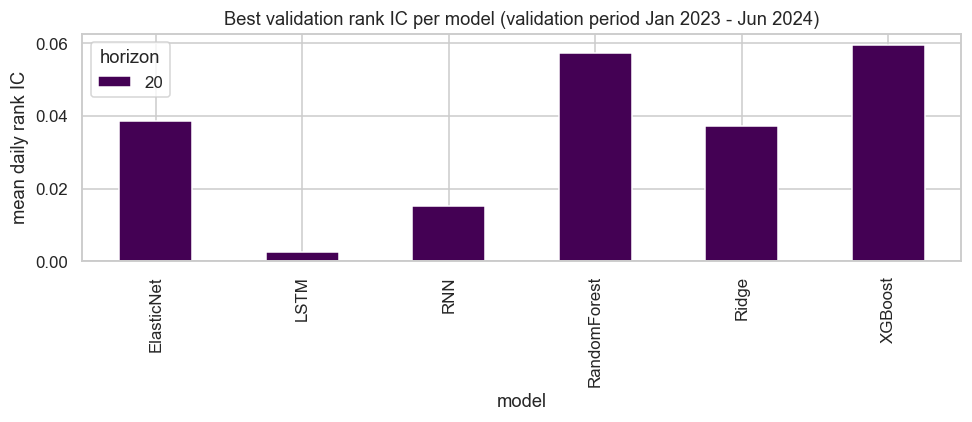

In [14]:
_tune_rows = [{"model": m, "h": h, "best validation IC": TUNING[(m, h)]["val_IC"].max()}
              for (m, h) in TUNING if m != "ARIMA"]
if _tune_rows:
    _t = pd.DataFrame(_tune_rows).pivot(index="model", columns="h", values="best validation IC")
    ax = _t.plot.bar(figsize=(9, 4), colormap="viridis")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title("Best validation rank IC per model (validation period Jan 2023 - Jun 2024)")
    ax.set_ylabel("mean daily rank IC"); ax.legend(title="horizon")
    plt.tight_layout(); savefig("tuning_validation_ic"); plt.show()

## 7. Feature selection

### 7.1 Permutation-importance methods (Carta et al., 2022)
On walk-forward folds inside the **train period (2019 – Dec 2022)**, so feature choice never sees validation or test data:
1. Train the **base model** on all features and compute its validation loss *L(Y, f(X))*.
2. For each feature *i*, permute it `N_PERMUTATIONS` times and compute the **normalised importance** (paper Eq. 2):
   $VI_i = \frac{1}{N}\sum_\pi \frac{L(Y, f(X^{\pi,i})) - L(Y, f(X))}{L(Y, f(X))}$.
   Negative VI means that replacing the feature with noise *lowers* the loss, so the feature is unimportant.
3. Removal strategies (with threshold *θ ≤ 0* and at most *K* removals):
   * **PI best**: among features with VI < 0, take the *K* with the **highest** VI and remove those below θ.
   * **PI worst**: among features with VI < 0, take the *K* with the **lowest** VI and remove those below θ.
   * **PI running**: among features with VI < θ, remove the *K* with the **highest** VI.
4. **Optimal threshold**: for every θ in [0, −0.025] (step 0.0001) and every K in {1, 3, 5, 7}, retrain without the removed features and
   compute the loss difference *L_base − L_new*. Keep the (θ, K) that maximises the mean loss difference across folds; if nothing improves, remove nothing.

The paper fits one model per stock or sector. Here the model is pooled across all stocks (one cross-sectional "sector"), so features are selected
for the whole universe. For RNN/LSTM the importances come from `PI_PROXY_FOR_NN` to keep run time reasonable.

### 7.2 Filter methods (for comparison)
* **corr_filter**: rank features by |mean daily rank IC| and greedily drop any feature with |ρ| > `CORR_THRESHOLD` to an already kept one.
* **mutual_info**: keep the top `MI_KEEP_FRAC` of features by mutual information with the label.
* **ic_tstat**: keep features whose daily rank IC has |t-stat| ≥ `IC_TSTAT_MIN`.

In [15]:
def fs_loss(rows, prob, h):
    if FS_LOSS == "mean_return":
        return -topk_spread(DPOS[rows], prob, FWD[h][rows])
    y = Y[h][rows]
    p = np.clip(prob, 1e-6, 1 - 1e-6)
    return log_loss(y, p, labels=[0, 1]) if FS_LOSS == "logloss" else brier_score_loss(y, p)

def filter_methods(h):
    path = RESULTS_DIR / "fs" / f"filters_h{h}.pkl"
    hit = cache_get(path)
    if hit is not None:
        return hit
    rows = labeled(rows_between(TRAIN0, V0 - 1 - h), h)
    rng = np.random.default_rng(SEED)
    samp = np.sort(rng.choice(rows, min(len(rows), FS_SAMPLE_ROWS), replace=False))
    stats = []
    for j, f in enumerate(FEATURE_COLS):
        ic = daily_ic(DPOS[rows], PANEL_X[rows, j], FWD[h][rows])
        stats.append({"feature": f, "IC_mean": ic.mean(),
                      "IC_t": ic.mean() / (ic.std() + 1e-12) * np.sqrt(len(ic))})
    stats = pd.DataFrame(stats).set_index("feature")
    Xs = np.nan_to_num(PANEL_X[samp])
    # corr filter
    corr = np.abs(np.corrcoef(Xs, rowvar=False))
    corr = np.nan_to_num(corr)
    kept = []
    for j in np.argsort(-stats["IC_mean"].abs().values):
        if all(corr[j, k] <= CORR_THRESHOLD for k in kept):
            kept.append(j)
    # mutual information
    mi = mutual_info_classif(Xs, Y[h][samp].astype(int), random_state=SEED)
    stats["MI"] = mi
    n_keep = max(MIN_FEATURES, int(round(MI_KEEP_FRAC * len(FEATURE_COLS))))
    mi_keep = np.argsort(-mi)[:n_keep]
    # IC t-stat
    t = stats["IC_t"].abs().values
    ic_keep = np.where(t >= IC_TSTAT_MIN)[0]
    if len(ic_keep) < MIN_FEATURES:
        ic_keep = np.argsort(-t)[:MIN_FEATURES]
    for j in np.argsort(-stats["IC_mean"].abs().values):
        if len(kept) >= MIN_FEATURES:
            break
        if j not in kept:
            kept.append(j)
    out = {"stats": stats,
           "corr_filter": np.sort(np.array(kept)),
           "mutual_info": np.sort(mi_keep),
           "ic_tstat": np.sort(ic_keep)}
    cache_put(path, out)
    return out

def removal_set(vi, strategy, K, thr):
    s = pd.Series(vi)
    if strategy == "PI_best":
        cand = s[s < 0].sort_values(ascending=False).head(K)
        rem = cand[cand < thr]
    elif strategy == "PI_worst":
        cand = s[s < 0].sort_values().head(K)
        rem = cand[cand < thr]
    else:  # PI_running
        rem = s[s < thr].sort_values(ascending=False).head(K)
    return frozenset(rem.index.tolist())

def pi_selection(model_name, h):
    """Carta et al. (2022) PI feature selection for one model and horizon. Returns all three strategies."""
    path = RESULTS_DIR / "fs" / f"PI_{model_name}_h{h}.pkl"
    hit = cache_get(path)
    if hit is not None:
        return hit
    params = BEST_PARAMS.get((model_name, h)) or tune_model(model_name, h)["best"]
    folds = make_folds(h, FS_VALID_FOLDS, "train")
    rng = np.random.default_rng(SEED)
    F = len(FEATURE_COLS)
    VI = np.zeros((len(folds), F))
    base_loss = []
    for fi, (tr, va) in enumerate(folds):
        m = build_model(model_name, params).fit(tr, ALL_COLS, h)
        Xva = PANEL_X[va].copy()
        L0 = fs_loss(va, m.predict_X(Xva), h)
        base_loss.append(L0)
        for j in range(F):
            orig = Xva[:, j].copy()
            d = []
            for _ in range(N_PERMUTATIONS):
                Xva[:, j] = orig[rng.permutation(len(orig))]
                d.append((fs_loss(va, m.predict_X(Xva), h) - L0) / abs(L0))
            Xva[:, j] = orig
            VI[fi, j] = np.mean(d)
    vi = VI.mean(axis=0)
    # candidate removal sets for every (strategy, K, threshold)
    grid = [(s, K, thr) for s in ["PI_best", "PI_worst", "PI_running"] for K in PI_K_LIST for thr in PI_THRESHOLDS]
    sets = {g: removal_set(vi, *g) for g in grid}
    diff_of = {frozenset(): 0.0}
    for rem in set(sets.values()) - {frozenset()}:
        if F - len(rem) < MIN_FEATURES:
            diff_of[rem] = -np.inf
            continue
        keep = np.array([j for j in range(F) if j not in rem])
        diffs = []
        for (tr, va), L0 in zip(folds, base_loss):
            m = build_model(model_name, params).fit(tr, keep, h)
            diffs.append(L0 - fs_loss(va, m.predict_proba(va, keep), h))
        diff_of[rem] = float(np.mean(diffs))
    curve = pd.DataFrame([{"strategy": s, "K": K, "threshold": thr, "n_removed": len(sets[(s, K, thr)]),
                           "loss_diff": diff_of[sets[(s, K, thr)]]} for (s, K, thr) in grid])
    out = {"VI": pd.Series(vi, index=FEATURE_COLS), "VI_folds": VI, "curve": curve, "base_loss": base_loss}
    for s in ["PI_best", "PI_worst", "PI_running"]:
        c = curve[curve.strategy == s]
        best = c.loc[c["loss_diff"].idxmax()]
        rem = sets[(s, int(best.K), float(best.threshold))] if best.loss_diff > 0 else frozenset()
        out[s] = np.array([j for j in range(F) if j not in rem])
        out[s + "_info"] = {"K": int(best.K), "threshold": float(best.threshold), "loss_diff": float(best.loss_diff),
                            "removed": [FEATURE_COLS[j] for j in sorted(rem)]}
    cache_put(path, out)
    return out

def selected_features(model_name, fs, h):
    if fs == "all" or model_name == "ARIMA":
        return ALL_COLS
    if fs in ("corr_filter", "mutual_info", "ic_tstat"):
        return filter_methods(h)[fs]
    pi_model = PI_PROXY_FOR_NN if model_name in ("RNN", "LSTM") else model_name
    return pi_selection(pi_model, h)[fs]

Run every feature-selection step now (cached), so its results can be inspected before the backtests.

In [16]:
FS_SELECTED = {}
for h in tqdm(HORIZONS, desc="Feature selection"):
    for m in MODELS:
        for fs in FS_METHODS:
            if m == "ARIMA" and fs != "all":
                continue
            FS_SELECTED[(m, fs, h)] = selected_features(m, fs, h)
_fs_table = pd.DataFrame([{"model": m, "fs": fs, "h": h, "n_features": len(c)} for (m, fs, h), c in FS_SELECTED.items()])
_fs_table.pivot_table(index=["model", "h"], columns="fs", values="n_features")

Feature selection:   0%|          | 0/1 [00:00<?, ?it/s]

,fs,PI_best,PI_running,PI_worst,all
model,h,,,,
ARIMA,20,NaN,NaN,NaN,56.0
ElasticNet,20,48.0,48.0,48.0,56.0
LSTM,20,31.0,31.0,31.0,56.0
RNN,20,31.0,31.0,31.0,56.0
RandomForest,20,51.0,49.0,41.0,56.0
Ridge,20,52.0,52.0,51.0,56.0
XGBoost,20,31.0,31.0,31.0,56.0


### 7.3 Feature-selection diagnostics

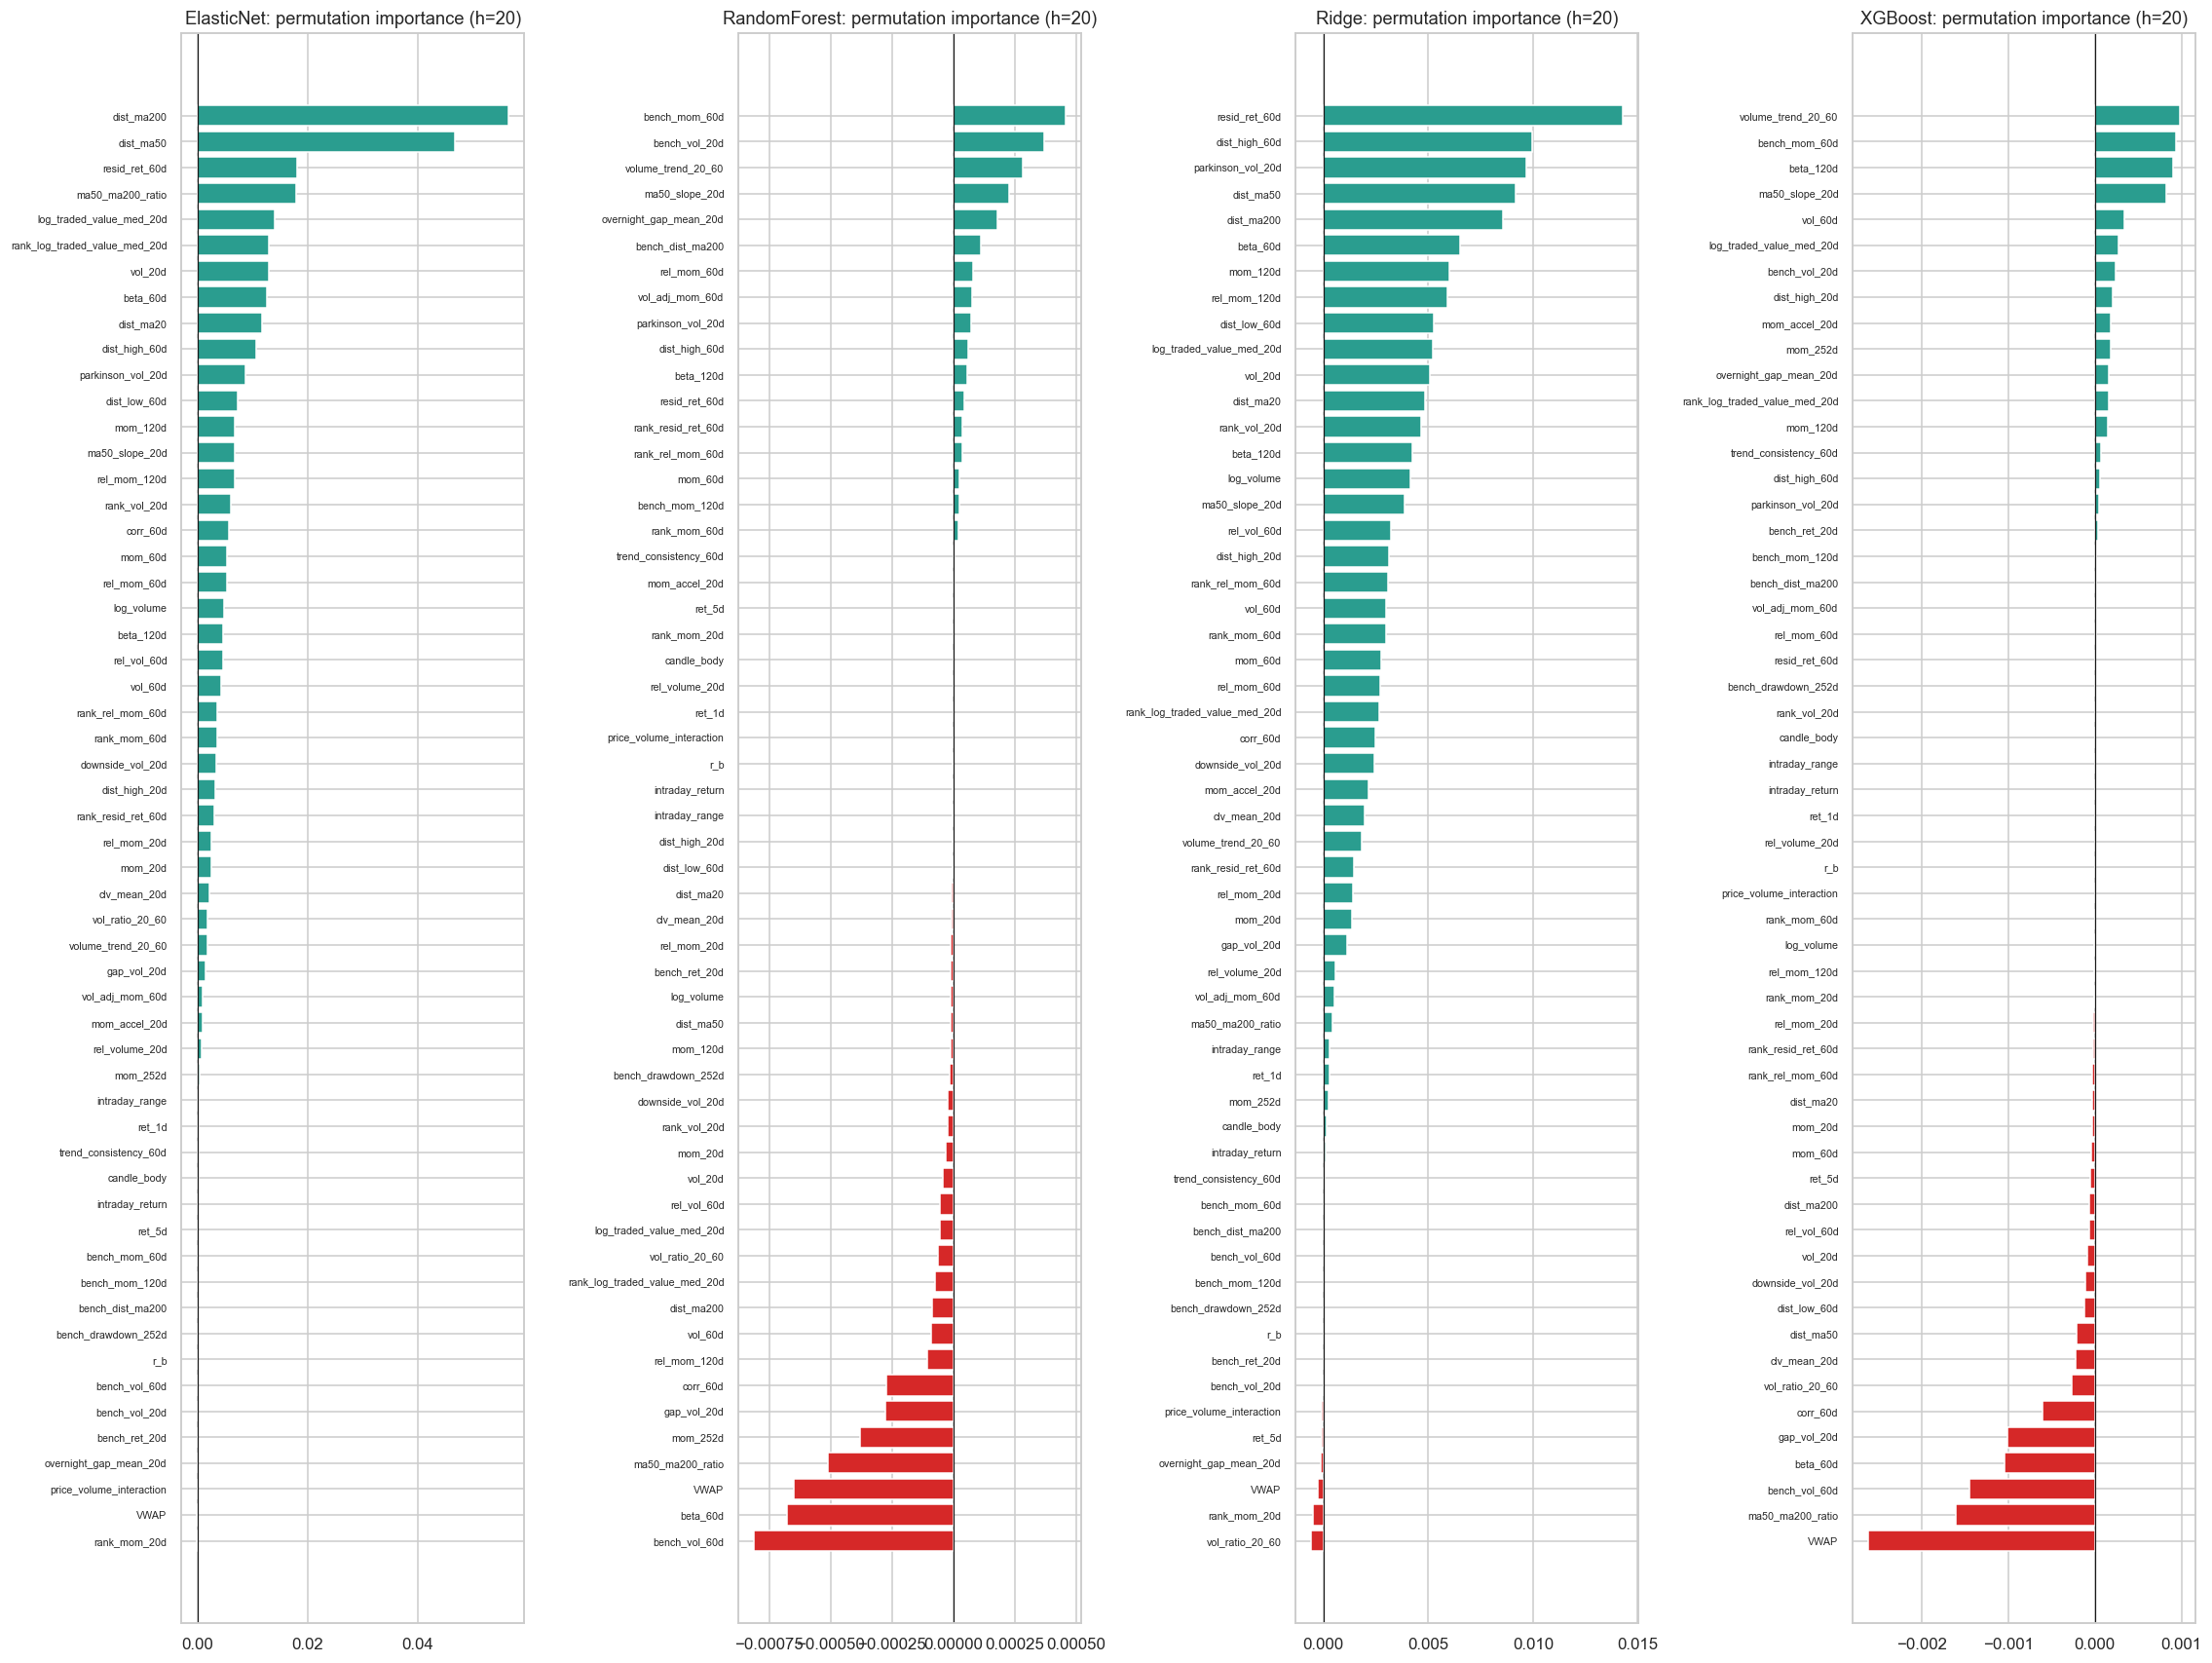

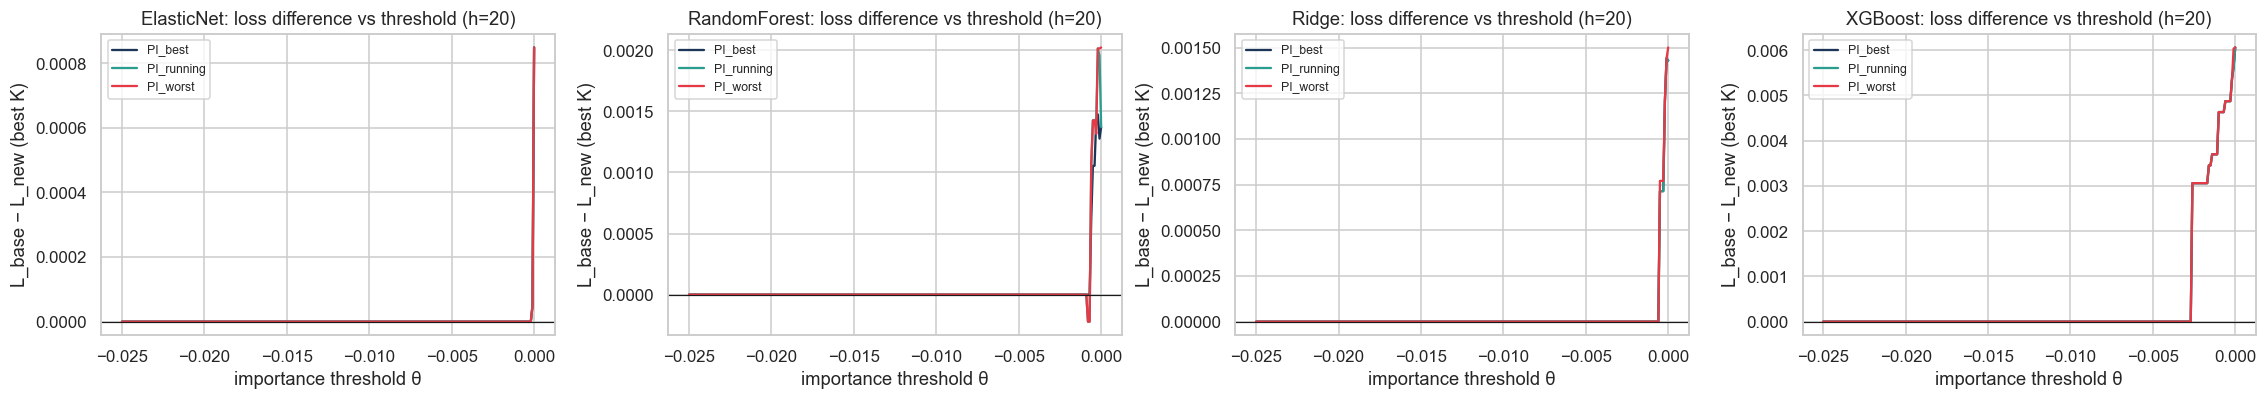

,model,h,strategy,K,threshold,loss_diff,removed
0,ElasticNet,20,PI_best,10,0.0000,0.000848,"[VWAP, r_b, bench_vol_60d, price_volume_intera..."
1,ElasticNet,20,PI_worst,10,0.0000,0.000848,"[VWAP, r_b, bench_vol_60d, price_volume_intera..."
2,ElasticNet,20,PI_running,10,0.0000,0.000848,"[VWAP, r_b, bench_vol_60d, price_volume_intera..."
3,RandomForest,20,PI_best,30,-0.0002,0.001474,"[VWAP, mom_252d, ma50_ma200_ratio, gap_vol_20d..."
4,RandomForest,20,PI_worst,15,0.0000,0.002022,"[VWAP, bench_vol_60d, mom_252d, rel_mom_120d, ..."
5,RandomForest,20,PI_running,7,-0.0002,0.002014,"[VWAP, bench_vol_60d, mom_252d, ma50_ma200_rat..."
6,Ridge,20,PI_best,10,-0.0001,0.001441,"[VWAP, vol_ratio_20_60, overnight_gap_mean_20d..."
7,Ridge,20,PI_worst,5,0.0000,0.001501,"[VWAP, ret_5d, vol_ratio_20_60, overnight_gap_..."
8,Ridge,20,PI_running,5,-0.0001,0.001441,"[VWAP, vol_ratio_20_60, overnight_gap_mean_20d..."
9,XGBoost,20,PI_best,25,0.0000,0.006060,"[VWAP, bench_vol_60d, ret_5d, mom_20d, mom_60d..."


In [17]:
PI_MODELS = sorted({m if m not in ("RNN", "LSTM") else PI_PROXY_FOR_NN
                    for m in MODELS if m != "ARIMA"}) if any(f.startswith("PI_") for f in FS_METHODS) else []
h0 = HORIZONS[0]
if PI_MODELS:
    n = len(PI_MODELS)
    fig, axes = plt.subplots(1, n, figsize=(5.2 * n, max(4, 0.28 * len(FEATURE_COLS))), squeeze=False)
    for ax, m in zip(axes[0], PI_MODELS):
        vi = pi_selection(m, h0)["VI"].sort_values()
        ax.barh(vi.index, vi.values, color=np.where(vi.values < 0, "#d62828", "#2a9d8f"))
        ax.axvline(0, color="k", lw=0.8)
        ax.set_title(f"{m}: permutation importance (h={h0})")
        ax.tick_params(axis="y", labelsize=7)
    plt.tight_layout(); savefig("pi_importance"); plt.show()

    fig, axes = plt.subplots(1, n, figsize=(5.2 * n, 3.8), squeeze=False)
    colors = {"PI_best": "#1d3557", "PI_worst": "#e63946", "PI_running": "#2a9d8f"}
    for ax, m in zip(axes[0], PI_MODELS):
        c = pi_selection(m, h0)["curve"]
        c = c[np.isfinite(c.loss_diff)].groupby(["strategy", "threshold"])["loss_diff"].max().reset_index()
        for s, d in c.groupby("strategy"):
            ax.plot(d.threshold, d.loss_diff, label=s, color=colors[s])
        ax.axhline(0, color="k", lw=0.8)
        ax.set_title(f"{m}: loss difference vs threshold (h={h0})")
        ax.set_xlabel("importance threshold θ"); ax.set_ylabel("L_base − L_new (best K)")
        ax.legend(fontsize=8)
    plt.tight_layout(); savefig("pi_threshold_curves"); plt.show()

    info = []
    for m in PI_MODELS:
        for h in HORIZONS:
            r = pi_selection(m, h)
            for s in ["PI_best", "PI_worst", "PI_running"]:
                info.append({"model": m, "h": h, "strategy": s, **r[s + "_info"]})
    display(pd.DataFrame(info))

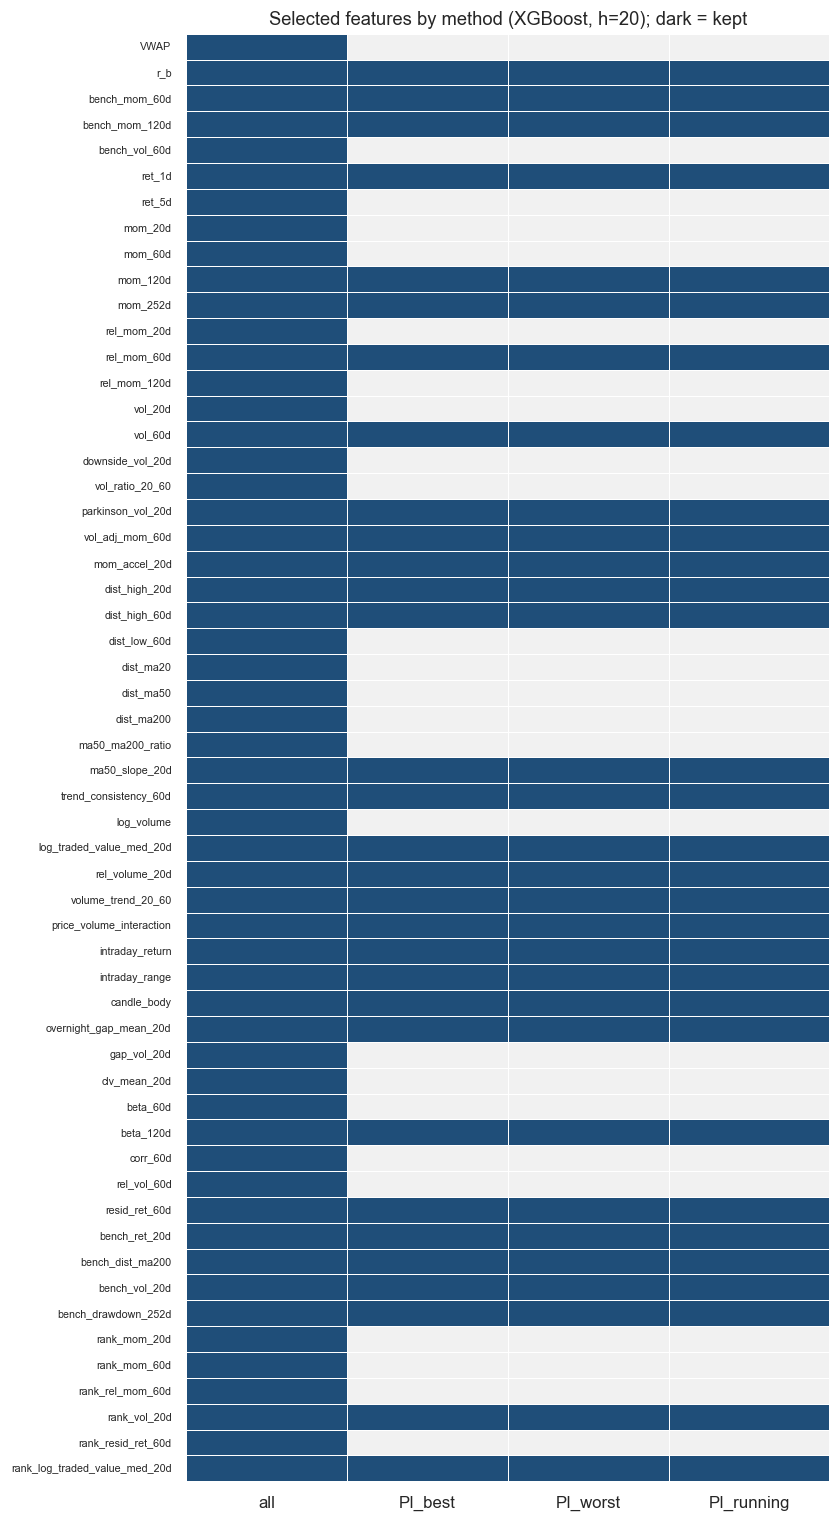

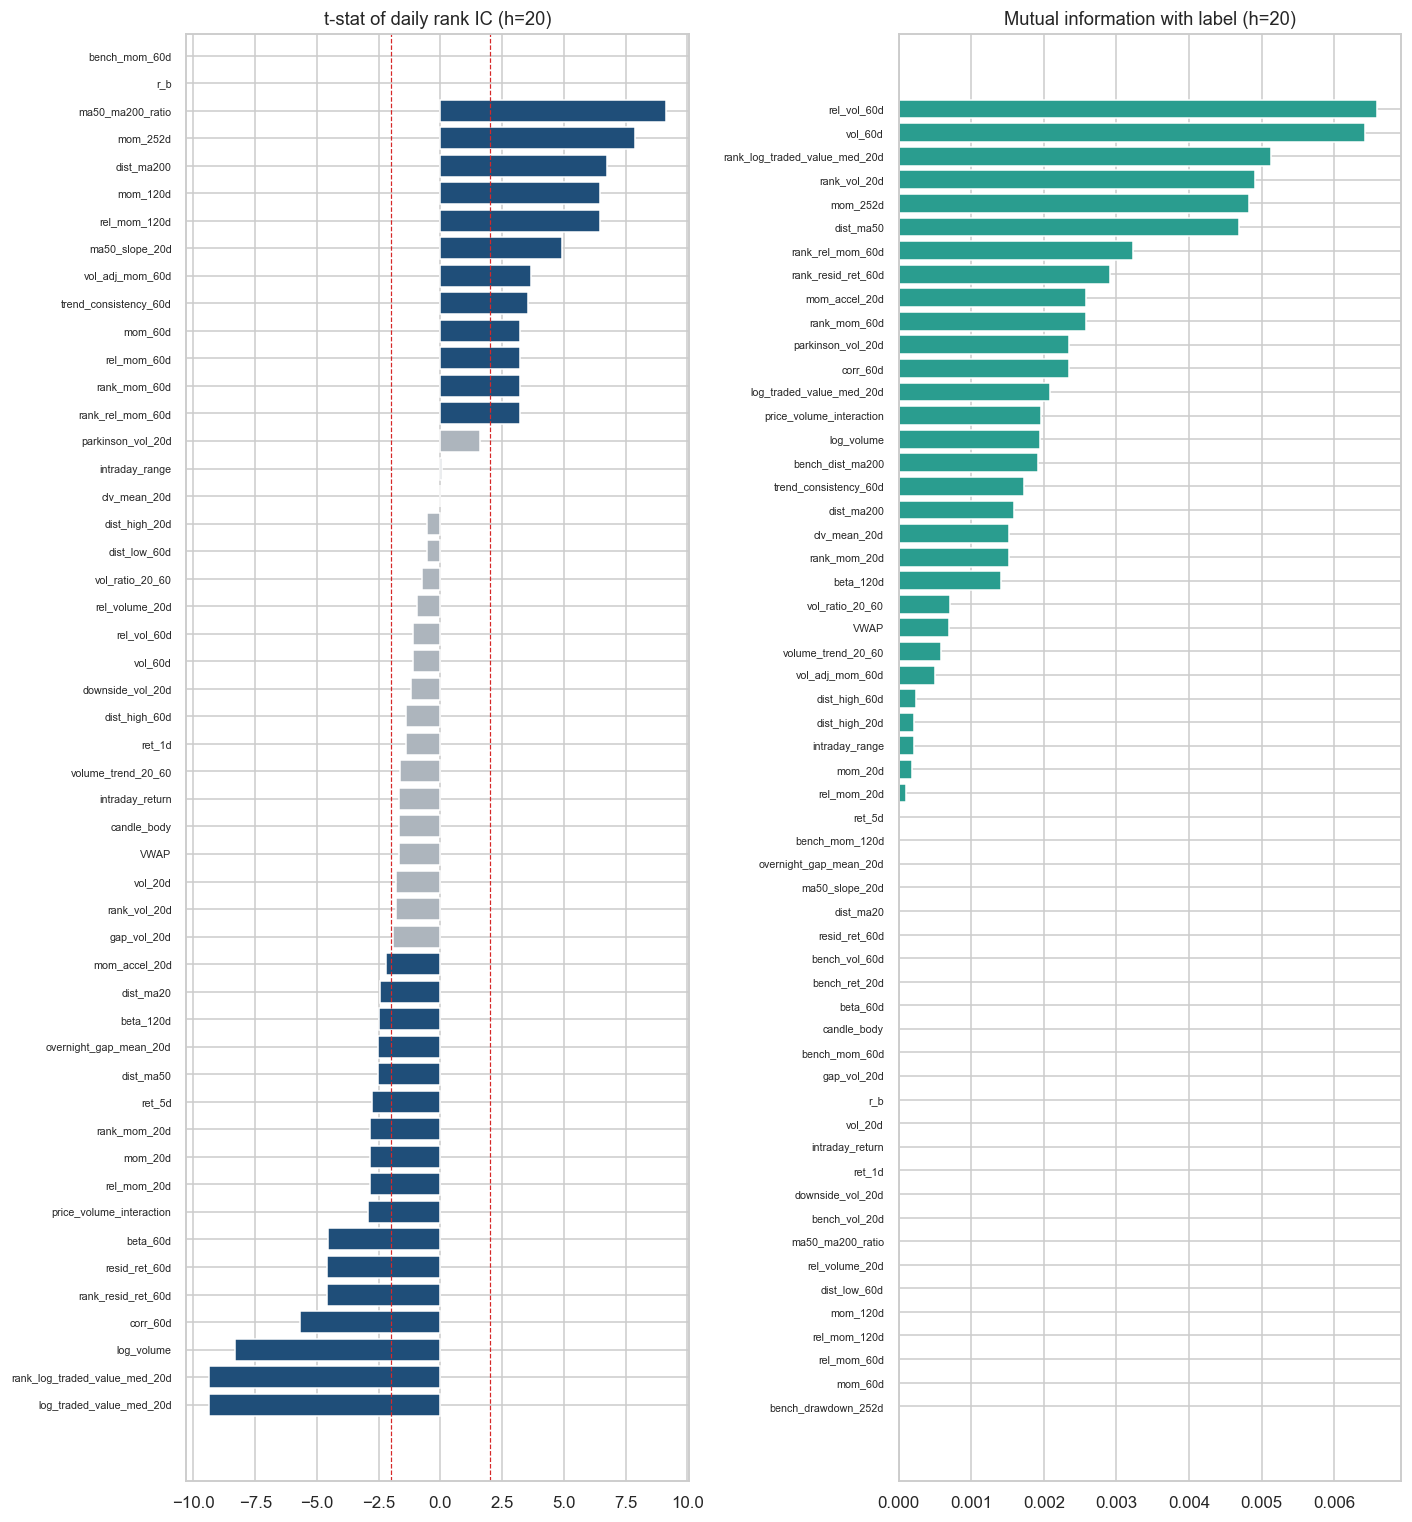

In [18]:
# which features each method keeps (first horizon, one representative model)
rep_model = next((m for m in ["XGBoost", "RandomForest", "Ridge", "ElasticNet"] if m in MODELS), MODELS[0])
mat = pd.DataFrame(0, index=FEATURE_COLS, columns=[f for f in FS_METHODS])
for fs in FS_METHODS:
    cols = FS_SELECTED.get((rep_model, fs, h0), ALL_COLS)
    mat.loc[FNAMES[cols], fs] = 1
plt.figure(figsize=(1.2 * len(FS_METHODS) + 3, max(4, 0.25 * len(FEATURE_COLS))))
sns.heatmap(mat, cmap=sns.color_palette(["#f1f1f1", "#1f4e79"]), cbar=False, linewidths=0.4, linecolor="white")
plt.title(f"Selected features by method ({rep_model}, h={h0}); dark = kept")
plt.yticks(fontsize=7); plt.tight_layout(); savefig("fs_selection_matrix"); plt.show()

st = filter_methods(h0)["stats"].sort_values("IC_t")
fig, axes = plt.subplots(1, 2, figsize=(13, max(4, 0.25 * len(FEATURE_COLS))))
axes[0].barh(st.index, st.IC_t, color=np.where(st.IC_t.abs() >= IC_TSTAT_MIN, "#1f4e79", "#adb5bd"))
for x in (-IC_TSTAT_MIN, IC_TSTAT_MIN):
    axes[0].axvline(x, color="#d62828", ls="--", lw=0.8)
axes[0].set_title(f"t-stat of daily rank IC (h={h0})"); axes[0].tick_params(axis="y", labelsize=7)
st2 = st.sort_values("MI")
axes[1].barh(st2.index, st2.MI, color="#2a9d8f"); axes[1].set_title(f"Mutual information with label (h={h0})")
axes[1].tick_params(axis="y", labelsize=7)
plt.tight_layout(); savefig("filter_stats"); plt.show()

## 8. Walk-forward prediction engine (test period Jul 2024 – Aug 2026)
For each (model, feature set, training method, horizon), the engine refits on the schedule from Section 4 and predicts a probability for
every stock on every test day. Predictions are cached in `RESULTS_DIR/preds`.

In [19]:
def generate_predictions(model_name, fs, method, h):
    path = RESULTS_DIR / "preds" / f"{model_name}__{fs}__{method}__h{h}.pkl"
    hit = cache_get(path)
    if hit is not None:
        return hit
    parts = []
    if model_name == "ARIMA":
        for P, end in refit_schedule(method):
            block, prob = arima_block(P, end, method, h)
            d, s = np.meshgrid(block, np.arange(N_SYMS), indexing="ij")
            parts.append(pd.DataFrame({"dpos": d.ravel(), "sid": s.ravel(), "prob": prob.ravel()}))
        out = pd.concat(parts, ignore_index=True)
        out = out[~np.isnan(CLOSE_W.values[out.dpos.values, out.sid.values])].dropna()
    else:
        cols = FS_SELECTED[(model_name, fs, h)] if (model_name, fs, h) in FS_SELECTED else selected_features(model_name, fs, h)
        params = BEST_PARAMS[(model_name, h)]
        for P, end in refit_schedule(method):
            a, b = train_range(P, method, h)
            tr = labeled(rows_between(a, b), h)
            te = rows_between(P, end)
            if len(tr) < 100 or len(te) == 0:
                continue
            m = build_model(model_name, params).fit(tr, cols, h)
            parts.append(pd.DataFrame({"dpos": DPOS[te], "sid": SID[te], "prob": m.predict_proba(te, cols), "row": te}))
        out = pd.concat(parts, ignore_index=True).dropna(subset=["prob"])
    cache_put(path, out)
    return out

def signal_metrics(pred, h):
    rows = (pred["dpos"].values, pred["sid"].values)
    fwd = (CLOSE_W.shift(-h) / CLOSE_W - 1).values[rows]
    t = pd.DataFrame({"d": pred.dpos.values, "p": pred.prob.values, "f": fwd}).dropna()
    if t.empty:
        return {"mean_IC": np.nan, "IC_IR": np.nan, "AUC": np.nan, "prec_top10": np.nan}, pd.Series(dtype=float)
    t["y"] = (t.f > t.groupby("d").f.transform("median")).astype(int)
    ic = daily_ic(t.d.values, t.p.values, t.f.values)
    auc = roc_auc_score(t.y, t.p) if t.y.nunique() == 2 else np.nan
    t["r"] = t.groupby("d").p.rank(ascending=False, method="first")
    prec = t[t.r <= 10].y.mean()
    ic.index = pd.to_datetime(DATES[ic.index.astype(int)])
    return {"mean_IC": ic.mean(), "IC_IR": ic.mean() / (ic.std() + 1e-12), "AUC": auc, "prec_top10": prec}, ic

## 9. Portfolio construction and backtest
* On each rebalance day: rank stocks by probability, go **long the top n_long** and **short the bottom n_short**.
* **Equal weight**: +1/n_long per long, −1/n_short per short (long leg sums to +1, short leg to −1; long-only portfolios sum to +1).
* **Markowitz**: $\max_w\; w^\top\mu - \frac{\lambda}{2} w^\top \Sigma w$ subject to long weights in [0, w_max] summing to 1 and short weights in [−w_max, 0] summing to −1.
  μ is the **past m-day rolling mean daily return** (proxy for expected return) and Σ is the Ledoit–Wolf covariance over `COV_LOOKBACK` days.
* Weights are held until the next rebalance (daily, or every *h* days). Daily P&L = Σ wᵢ · rᵢ(t→t+1). **No costs**.

In [20]:
_MKW_CACHE = {}

def markowitz_weights(p, longs, shorts, m):
    key = (p, tuple(longs), tuple(shorts), m)
    if key in _MKW_CACHE:
        return _MKW_CACHE[key]
    sel = np.r_[longs, shorts].astype(int)
    nl, ns = len(longs), len(shorts)
    hist_mu = RD[max(0, p - m + 1):p + 1, sel]
    mu = np.nan_to_num(np.nanmean(hist_mu, axis=0))
    hist = np.nan_to_num(RD[max(0, p - COV_LOOKBACK + 1):p + 1, sel])
    Sigma = LedoitWolf().fit(hist).covariance_ if len(hist) > 5 else np.eye(len(sel)) * 1e-4
    wmax_l = max(W_MAX, 1.0 / nl + 1e-9)
    wmax_s = max(W_MAX, 1.0 / ns + 1e-9) if ns else 0
    x0 = np.r_[np.full(nl, 1.0 / nl), np.full(ns, -1.0 / ns) if ns else []]
    bounds = [(0, wmax_l)] * nl + [(-wmax_s, 0)] * ns
    cons = [{"type": "eq", "fun": lambda w: w[:nl].sum() - 1.0}]
    if ns:
        cons.append({"type": "eq", "fun": lambda w: w[nl:].sum() + 1.0})
    obj = lambda w: -(w @ mu - 0.5 * RISK_AVERSION * w @ Sigma @ w)
    jac = lambda w: -(mu - RISK_AVERSION * Sigma @ w)
    try:
        r = minimize(obj, x0, jac=jac, bounds=bounds, constraints=cons, method="SLSQP", options={"maxiter": 200})
        w = r.x if r.success else x0
    except Exception:
        w = x0
    _MKW_CACHE[key] = w
    return w

BT_POS = np.array([p for p in range(T0, TEND + 1) if np.isfinite(RN[p]).any()])
BENCH = pd.Series(np.nanmean(RN[BT_POS], axis=1), index=pd.to_datetime(DATES[BT_POS]), name="EW benchmark")

def backtest(pred, n_long, n_short, weighting, mu_lb, h):
    P = np.full((N_DATES, N_SYMS), np.nan)
    P[pred.dpos.values, pred.sid.values] = pred.prob.values
    w_prev = np.zeros(N_SYMS)
    w = np.zeros(N_SYMS)
    port, longs_r, shorts_r, turn = [], [], [], []
    for k, p in enumerate(BT_POS):
        if REBALANCE == "daily" or k % h == 0:
            probs = P[p]
            valid = np.where(np.isfinite(probs) & np.isfinite(CLOSE_W.values[p]))[0]
            w = np.zeros(N_SYMS)
            if len(valid) >= n_long + n_short:
                order = valid[np.argsort(probs[valid], kind="stable")]
                L = order[-n_long:][::-1]
                S = order[:n_short] if n_short else np.array([], dtype=int)
                if weighting == "equal":
                    w[L] = 1.0 / n_long
                    if n_short:
                        w[S] = -1.0 / n_short
                else:
                    ww = markowitz_weights(p, L, S, mu_lb)
                    w[L] = ww[:n_long]
                    if n_short:
                        w[S] = ww[n_long:]
        r = np.nan_to_num(RN[p])
        port.append(w @ r)
        longs_r.append(w[w > 0] @ r[w > 0])
        shorts_r.append(w[w < 0] @ r[w < 0])
        turn.append(np.abs(w - w_prev).sum())
        w_prev = w
    idx = pd.to_datetime(DATES[BT_POS])
    return pd.DataFrame({"ret": port, "long": longs_r, "short": shorts_r, "turnover": turn}, index=idx)

def perf_metrics(r):
    r = pd.Series(r).dropna()
    n = len(r)
    if n < 2 or r.std() == 0:
        return dict(ann_return=np.nan, ann_vol=np.nan, sharpe=np.nan, sortino=np.nan, max_dd=np.nan,
                    calmar=np.nan, hit_rate=np.nan, total_return=np.nan)
    total = (1 + r).prod() - 1
    ann_ret = (1 + total) ** (252 / n) - 1
    vol = r.std() * np.sqrt(252)
    down = r[r < 0].std() * np.sqrt(252)
    eq = (1 + r).cumprod()
    mdd = (eq / eq.cummax() - 1).min()
    return dict(ann_return=ann_ret, ann_vol=vol, sharpe=r.mean() / r.std() * np.sqrt(252),
                sortino=r.mean() * 252 / down if down > 0 else np.nan, max_dd=mdd,
                calmar=ann_ret / abs(mdd) if mdd < 0 else np.nan, hit_rate=(r > 0).mean(), total_return=total)

print("Benchmark (equal-weighted universe, test period):")
pd.Series(perf_metrics(BENCH)).round(4)

Benchmark (equal-weighted universe, test period):


ann_return      0.0761
ann_vol         0.1749
sharpe          0.5069
sortino         0.6673
max_dd         -0.2010
calmar          0.3785
hit_rate        0.5583
total_return    0.1674
dtype: float64

## 10. Run the full experiment grid
Loops over **model × feature selection × training method × horizon**, then over **portfolio × weighting × m** for each prediction set.
Runs are cached, so re-running this cell skips finished work. Failures are logged and skipped.

In [21]:
combos = [(m, fs, tm, h) for m in MODELS for fs in FS_METHODS for tm in TRAIN_METHODS for h in HORIZONS
          if not (m == "ARIMA" and fs != "all")]
n_variants = len(PORTFOLIOS) * sum(len(MU_LOOKBACKS) if w == "markowitz" else 1 for w in WEIGHTINGS)
print(f"{len(combos)} prediction runs x {n_variants} portfolio variants = {len(combos) * n_variants} backtests")

ROWS, SERIES, ICS, FAILED = [], {}, {}, []
t_start = time.time()
for (m, fs, tm, h) in tqdm(combos, desc="Experiments"):
    try:
        pred = generate_predictions(m, fs, tm, h)
        sig, ic = signal_metrics(pred, h)
        ICS[(m, fs, tm, h)] = ic
        n_feat = 0 if m == "ARIMA" else len(FS_SELECTED[(m, fs, h)] if (m, fs, h) in FS_SELECTED else ALL_COLS)
        for pname, (nl, ns) in PORTFOLIOS.items():
            for wgt in WEIGHTINGS:
                for mu_lb in (MU_LOOKBACKS if wgt == "markowitz" else [None]):
                    bt = backtest(pred, nl, ns, wgt, mu_lb, h)
                    sid_ = f"{m} | {fs} | {tm} | h{h} | {pname} | {wgt}" + (f"(m={mu_lb})" if mu_lb else "")
                    SERIES[sid_] = bt
                    ROWS.append({"strategy": sid_, "model": m, "fs": fs, "train_method": tm, "horizon": h,
                                 "portfolio": pname, "weighting": wgt if wgt == "equal" else f"markowitz_m{mu_lb}",
                                 "n_features": n_feat, **perf_metrics(bt["ret"]),
                                 "long_ann_ret": perf_metrics(bt["long"])["ann_return"],
                                 "short_contrib_ann": bt["short"].mean() * 252,
                                 "avg_turnover": bt["turnover"].mean(), **sig})
    except Exception as e:
        FAILED.append(((m, fs, tm, h), repr(e)))
        print(f"FAILED {m} {fs} {tm} h{h}: {e!r}")

RESULTS = pd.DataFrame(ROWS)
RESULTS.to_csv(RESULTS_DIR / "leaderboard.csv", index=False)
cache_put(RESULTS_DIR / "series.pkl", {"series": SERIES, "ics": ICS, "bench": BENCH})
print(f"Done in {(time.time() - t_start) / 60:.1f} min | {len(RESULTS)} backtests | {len(FAILED)} failed runs")

25 prediction runs x 1 portfolio variants = 25 backtests


Experiments:   0%|          | 0/25 [00:00<?, ?it/s]

Done in 198.5 min | 25 backtests | 0 failed runs


## 11. Results
### 11.1 Leaderboard
All figures are out-of-sample on the test period (Jul 2024 – Aug 2026); hyperparameters and features were fixed before it started.

In [22]:
show_cols = ["strategy", "sharpe", "ann_return", "ann_vol", "max_dd", "sortino", "calmar", "hit_rate",
             "mean_IC", "IC_IR", "AUC", "prec_top10", "avg_turnover", "n_features"]
bench_m = perf_metrics(BENCH)
print(f"EW benchmark -> Sharpe {bench_m['sharpe']:.2f} | ann. return {bench_m['ann_return']:.2%} | max DD {bench_m['max_dd']:.2%}")
(RESULTS.sort_values("sharpe", ascending=False)[show_cols].head(25)
 .style.format({"sharpe": "{:.2f}", "ann_return": "{:.1%}", "ann_vol": "{:.1%}", "max_dd": "{:.1%}",
                "sortino": "{:.2f}", "calmar": "{:.2f}", "hit_rate": "{:.1%}", "mean_IC": "{:.3f}",
                "IC_IR": "{:.2f}", "AUC": "{:.3f}", "prec_top10": "{:.1%}", "avg_turnover": "{:.2f}"})
 .background_gradient(subset=["sharpe"], cmap="RdYlGn"))

EW benchmark -> Sharpe 0.51 | ann. return 7.61% | max DD -20.10%


,strategy,sharpe,ann_return,ann_vol,max_dd,sortino,calmar,hit_rate,mean_IC,IC_IR,AUC,prec_top10,avg_turnover,n_features
13,XGBoost | PI_best | expanding | h20 | L5S5 | markowitz(m=20),1.36,48.0%,32.9%,-36.0%,2.29,1.33,53.0%,0.045,0.34,0.516,53.2%,1.31,31
15,XGBoost | PI_running | expanding | h20 | L5S5 | markowitz(m=20),1.36,48.0%,32.9%,-36.0%,2.29,1.33,53.0%,0.045,0.34,0.516,53.2%,1.31,31
14,XGBoost | PI_worst | expanding | h20 | L5S5 | markowitz(m=20),1.36,48.0%,32.9%,-36.0%,2.29,1.33,53.0%,0.045,0.34,0.516,53.2%,1.31,31
24,ARIMA | all | expanding | h20 | L5S5 | markowitz(m=20),1.28,44.6%,33.1%,-26.1%,2.30,1.71,50.4%,-0.002,-0.01,0.499,50.0%,1.28,0
16,RNN | all | expanding | h20 | L5S5 | markowitz(m=20),1.20,29.8%,24.2%,-29.2%,1.93,1.02,49.4%,0.031,0.34,0.512,51.4%,1.49,56
11,RandomForest | PI_running | expanding | h20 | L5S5 | markowitz(m=20),1.17,37.2%,31.4%,-23.9%,1.65,1.56,52.4%,0.021,0.17,0.505,55.8%,1.31,49
19,RNN | PI_running | expanding | h20 | L5S5 | markowitz(m=20),1.05,29.5%,28.6%,-32.9%,1.42,0.90,51.7%,0.032,0.29,0.508,56.0%,1.57,31
18,RNN | PI_worst | expanding | h20 | L5S5 | markowitz(m=20),1.05,29.5%,28.6%,-32.9%,1.42,0.90,51.7%,0.032,0.29,0.508,56.0%,1.57,31
17,RNN | PI_best | expanding | h20 | L5S5 | markowitz(m=20),1.05,29.5%,28.6%,-32.9%,1.42,0.90,51.7%,0.032,0.29,0.508,56.0%,1.57,31
9,RandomForest | PI_best | expanding | h20 | L5S5 | markowitz(m=20),0.97,28.9%,31.1%,-27.5%,1.36,1.05,53.0%,0.024,0.19,0.507,55.2%,1.27,51


In [38]:
# best configuration per model
best_per_model = RESULTS.loc[RESULTS.groupby("model")["sharpe"].idxmax()].sort_values("sharpe", ascending=False)

cols = ["model", "fs", "train_method", "horizon", "portfolio", "weighting",
        "sharpe", "ann_return", "ann_vol", "max_dd", "sortino", "calmar", "hit_rate",
        "mean_IC", "IC_IR", "AUC", "prec_top10", "avg_turnover", "n_features"]

(best_per_model[cols].reset_index(drop=True)
 .style.format({"sharpe": "{:.2f}", "ann_return": "{:.1%}", "ann_vol": "{:.1%}", "max_dd": "{:.1%}",
                "sortino": "{:.2f}", "calmar": "{:.2f}", "hit_rate": "{:.1%}", "mean_IC": "{:.4f}",
                "IC_IR": "{:.3f}", "AUC": "{:.3f}", "prec_top10": "{:.1%}", "avg_turnover": "{:.2f}",
                "n_features": "{:.0f}"})
 .background_gradient(subset=["sharpe"], cmap="RdYlGn"))

,model,fs,train_method,horizon,portfolio,weighting,sharpe,ann_return,ann_vol,max_dd,sortino,calmar,hit_rate,mean_IC,IC_IR,AUC,prec_top10,avg_turnover,n_features
0,XGBoost,PI_best,expanding,20,L5S5,markowitz_m20,1.36,48.0%,32.9%,-36.0%,2.29,1.33,53.0%,0.0447,0.337,0.516,53.2%,1.31,31
1,ARIMA,all,expanding,20,L5S5,markowitz_m20,1.28,44.6%,33.1%,-26.1%,2.30,1.71,50.4%,-0.0021,-0.013,0.499,50.0%,1.28,0
2,RNN,all,expanding,20,L5S5,markowitz_m20,1.20,29.8%,24.2%,-29.2%,1.93,1.02,49.4%,0.0308,0.342,0.512,51.4%,1.49,56
3,RandomForest,PI_running,expanding,20,L5S5,markowitz_m20,1.17,37.2%,31.4%,-23.9%,1.65,1.56,52.4%,0.0209,0.169,0.505,55.8%,1.31,49
4,LSTM,PI_best,expanding,20,L5S5,markowitz_m20,0.96,24.5%,26.5%,-27.2%,1.29,0.90,53.8%,0.0466,0.472,0.521,53.1%,1.41,31
5,Ridge,PI_best,expanding,20,L5S5,markowitz_m20,0.31,4.9%,34.7%,-35.7%,0.44,0.14,51.7%,0.0050,0.045,0.500,49.5%,1.23,52
6,ElasticNet,PI_worst,expanding,20,L5S5,markowitz_m20,0.11,-2.4%,35.2%,-44.7%,0.15,-0.05,50.6%,0.0084,0.078,0.502,50.4%,1.23,48


### 11.2 Cumulative returns: best strategy per model vs benchmark

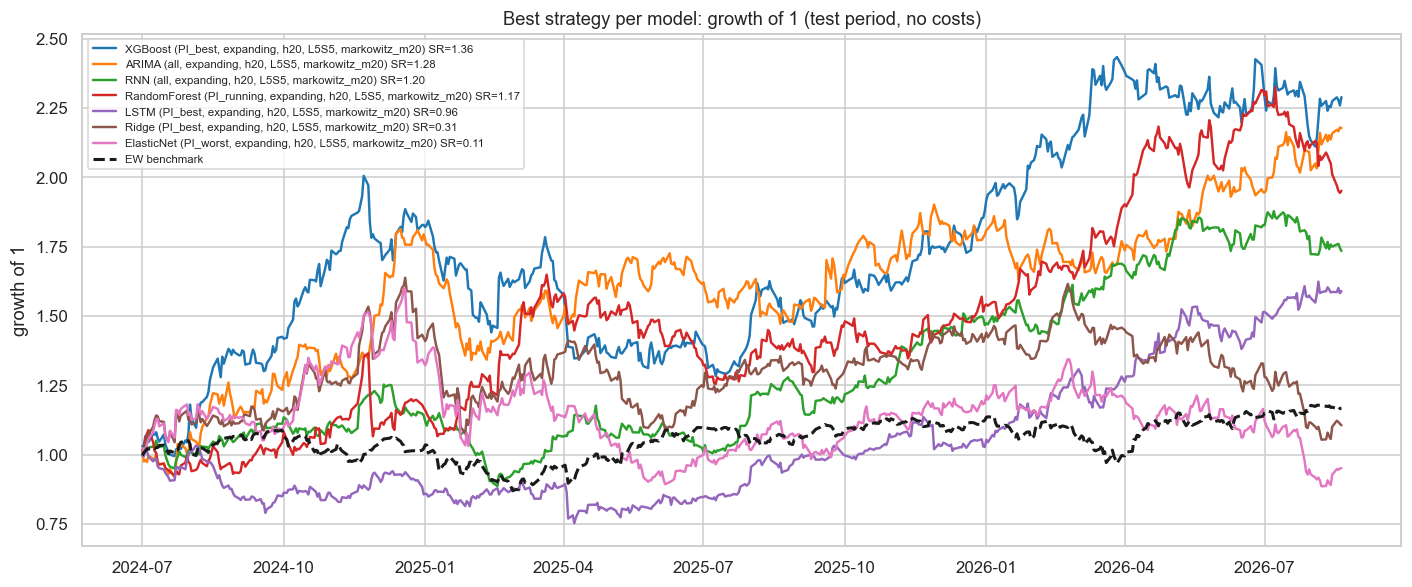

In [24]:
fig, ax = plt.subplots(figsize=(13, 5.5))
pal = sns.color_palette("tab10", len(best_per_model))
for c, (_, r) in zip(pal, best_per_model.iterrows()):
    eq = (1 + SERIES[r.strategy]["ret"]).cumprod()
    ax.plot(eq.index, eq.values, color=c, lw=1.6, label=f"{r.model} ({r.fs}, {r.train_method}, h{r.horizon}, {r.portfolio}, {r.weighting}) SR={r.sharpe:.2f}")
ax.plot(BENCH.index, (1 + BENCH).cumprod().values, color="k", lw=2, ls="--", label="EW benchmark")
ax.set_title("Best strategy per model: growth of 1 (test period, no costs)")
ax.legend(fontsize=7.5, loc="upper left"); ax.set_ylabel("growth of 1")
plt.tight_layout(); savefig("cum_best_per_model"); plt.show()

### 11.3 Which choices matter? Sharpe ratio by each design dimension

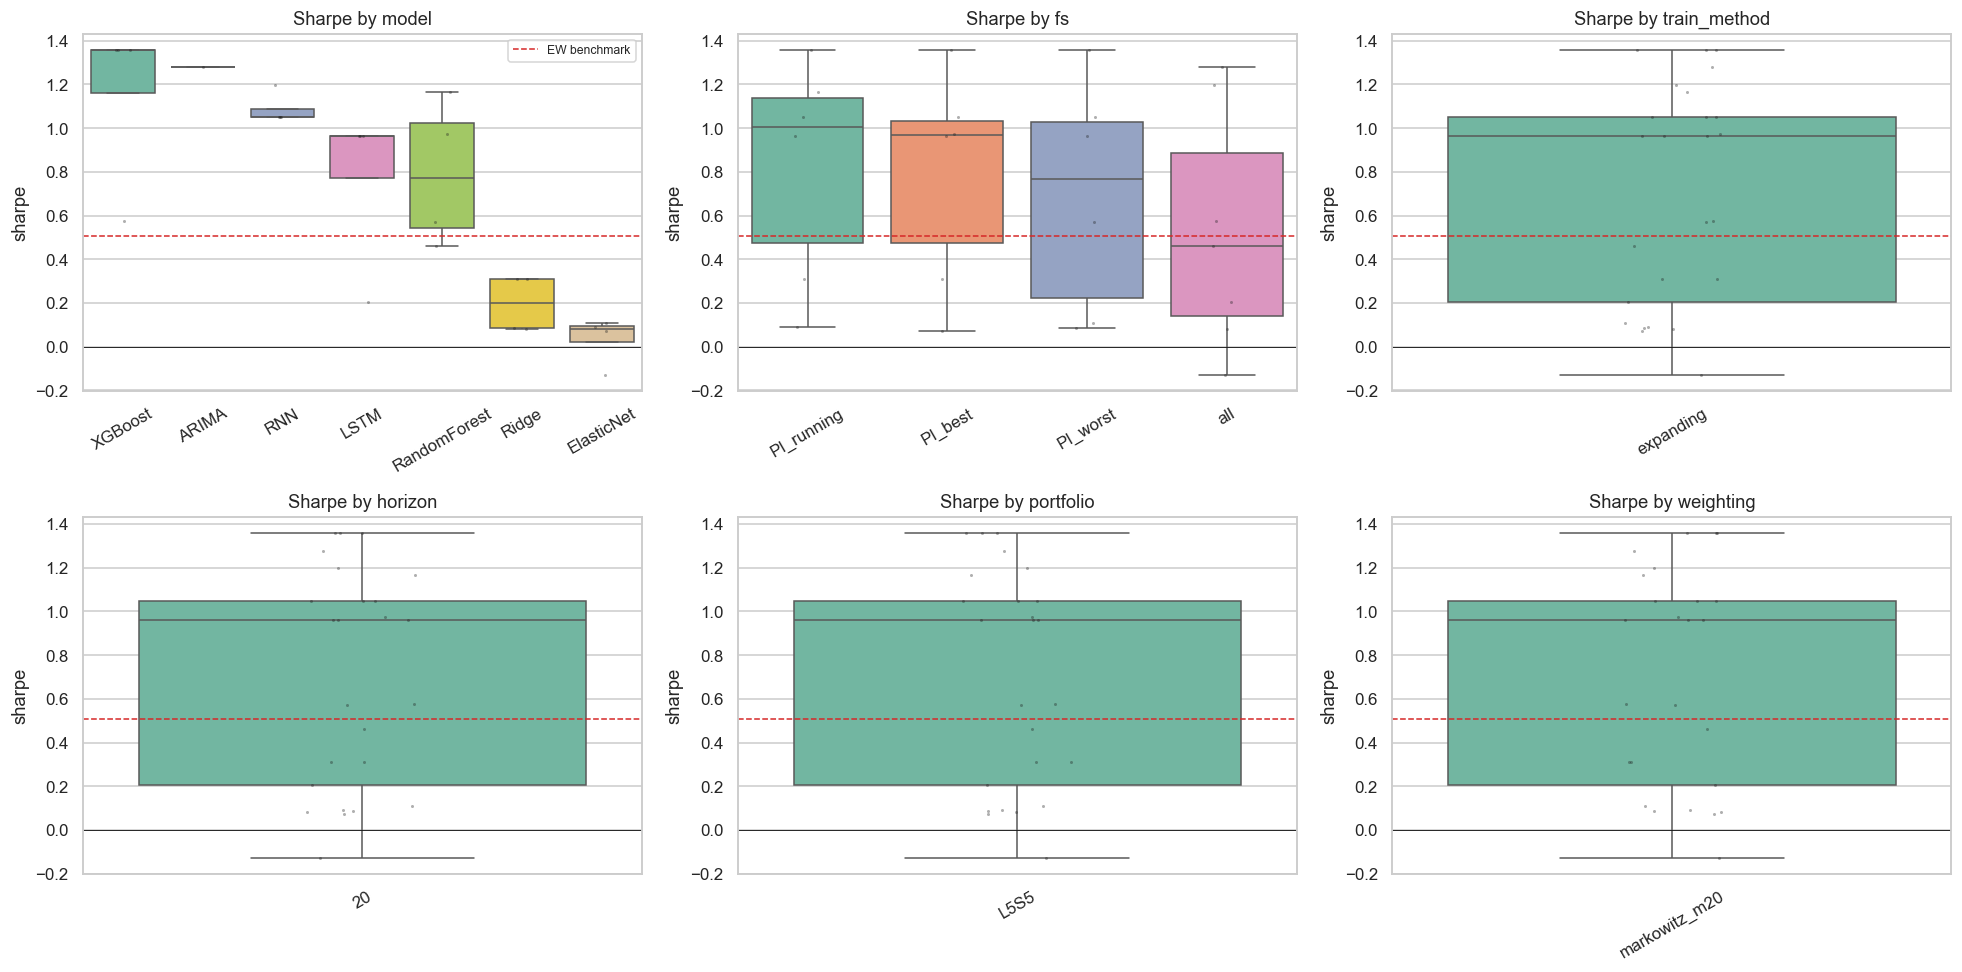

In [25]:
dims = ["model", "fs", "train_method", "horizon", "portfolio", "weighting"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, d in zip(axes.ravel(), dims):
    order = RESULTS.groupby(d)["sharpe"].median().sort_values(ascending=False).index
    sns.boxplot(data=RESULTS, x=d, y="sharpe", order=order, ax=ax, palette="Set2", showfliers=False)
    sns.stripplot(data=RESULTS, x=d, y="sharpe", order=order, ax=ax, color="k", size=2, alpha=0.35)
    ax.axhline(bench_m["sharpe"], color="#d62828", ls="--", lw=1, label="EW benchmark")
    ax.axhline(0, color="k", lw=0.6)
    ax.set_title(f"Sharpe by {d}"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); savefig("sharpe_by_dimension"); plt.show()

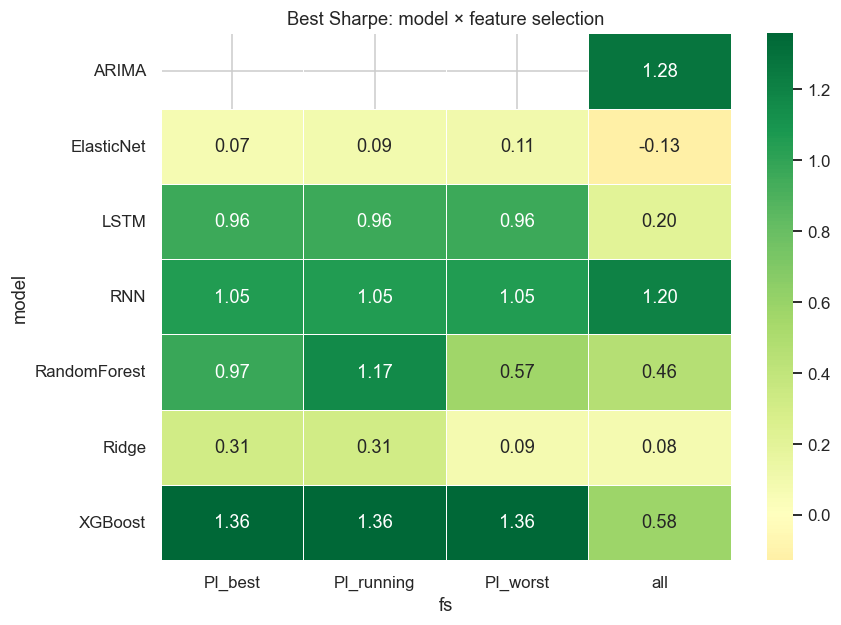

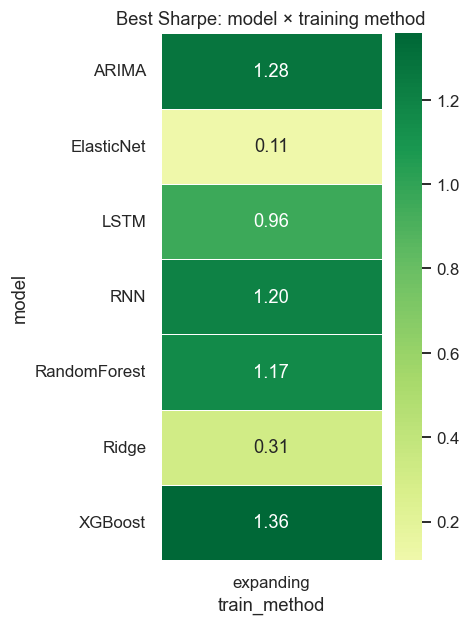

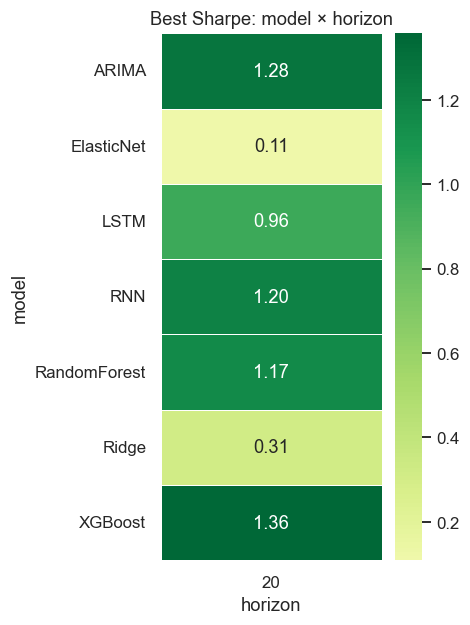

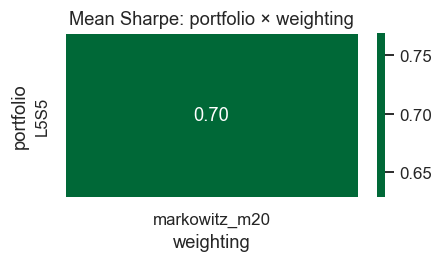

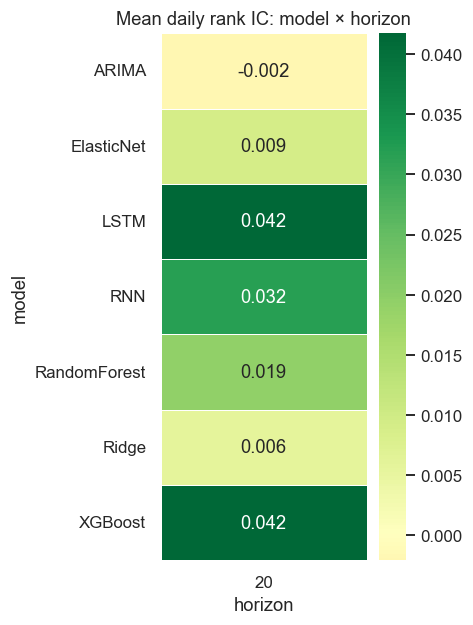

In [26]:
def heat(index, columns, value="sharpe", agg="max", title=None, fmt=".2f", name=None):
    t = RESULTS.pivot_table(index=index, columns=columns, values=value, aggfunc=agg)
    plt.figure(figsize=(1.3 * t.shape[1] + 3, 0.55 * t.shape[0] + 2))
    sns.heatmap(t, annot=True, fmt=fmt, cmap="RdYlGn", center=0 if value != "AUC" else 0.5, linewidths=0.5)
    plt.title(title or f"{agg} {value}: {index} x {columns}")
    plt.tight_layout()
    if name:
        savefig(name)
    plt.show()

heat("model", "fs", title="Best Sharpe: model × feature selection", name="heat_model_fs")
heat("model", "train_method", title="Best Sharpe: model × training method", name="heat_model_train")
heat("model", "horizon", title="Best Sharpe: model × horizon", name="heat_model_horizon")
heat("portfolio", "weighting", agg="mean", title="Mean Sharpe: portfolio × weighting", name="heat_port_weight")
heat("model", "horizon", value="mean_IC", agg="mean", fmt=".3f", title="Mean daily rank IC: model × horizon", name="heat_ic")

### 11.4 Risk: drawdowns, rolling Sharpe and monthly returns of the top strategies

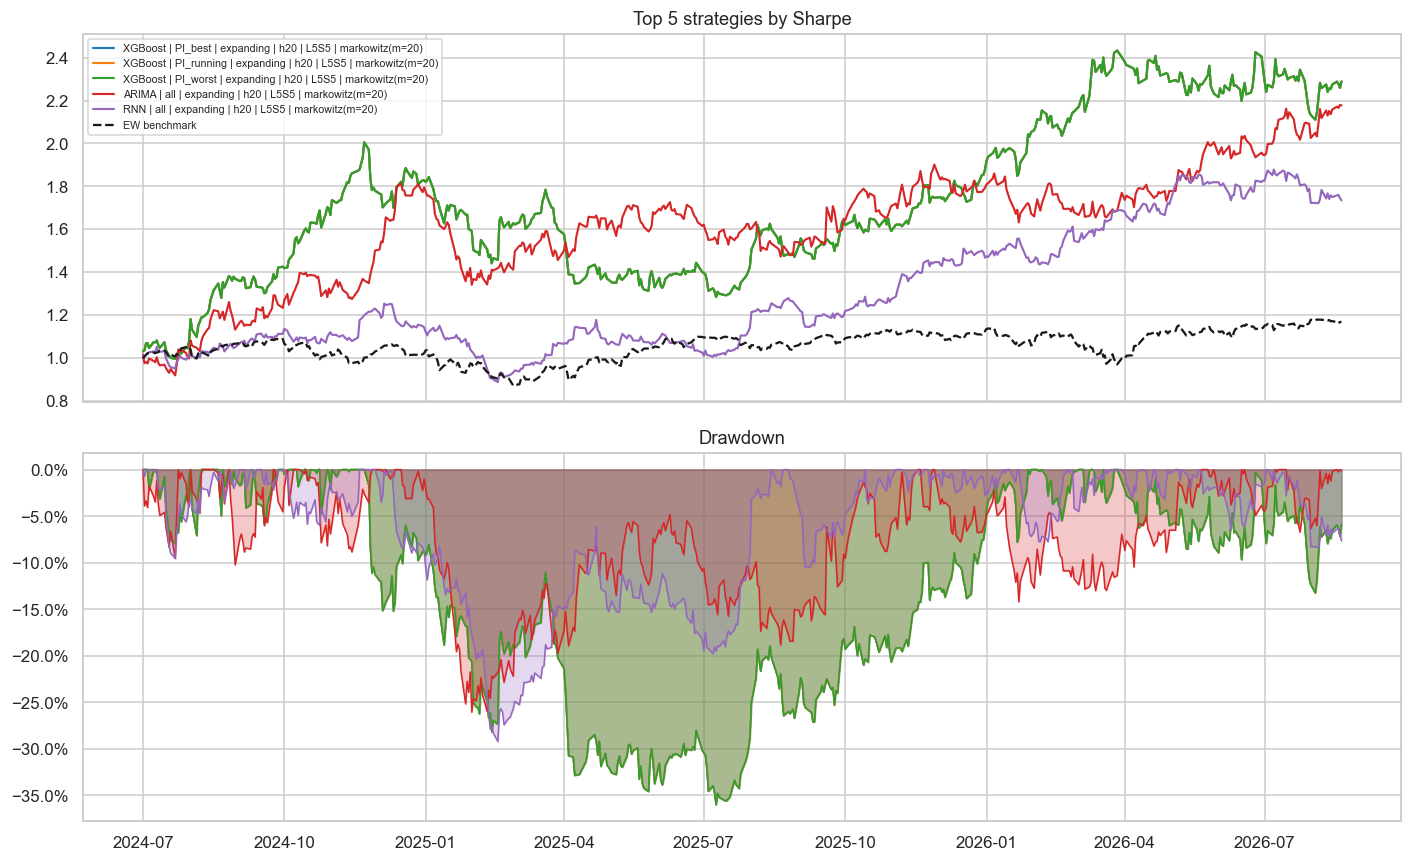

In [27]:
top5 = RESULTS.sort_values("sharpe", ascending=False).head(5)
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for c, (_, r) in zip(sns.color_palette("tab10", 5), top5.iterrows()):
    s = SERIES[r.strategy]["ret"]
    eq = (1 + s).cumprod()
    axes[0].plot(eq.index, eq, color=c, label=r.strategy, lw=1.4)
    axes[1].fill_between(eq.index, eq / eq.cummax() - 1, 0, color=c, alpha=0.25)
    axes[1].plot(eq.index, eq / eq.cummax() - 1, color=c, lw=1)
axes[0].plot(BENCH.index, (1 + BENCH).cumprod(), "k--", lw=1.5, label="EW benchmark")
axes[0].set_title("Top 5 strategies by Sharpe"); axes[0].legend(fontsize=7)
axes[1].set_title("Drawdown"); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.tight_layout(); savefig("top5_equity_drawdown"); plt.show()

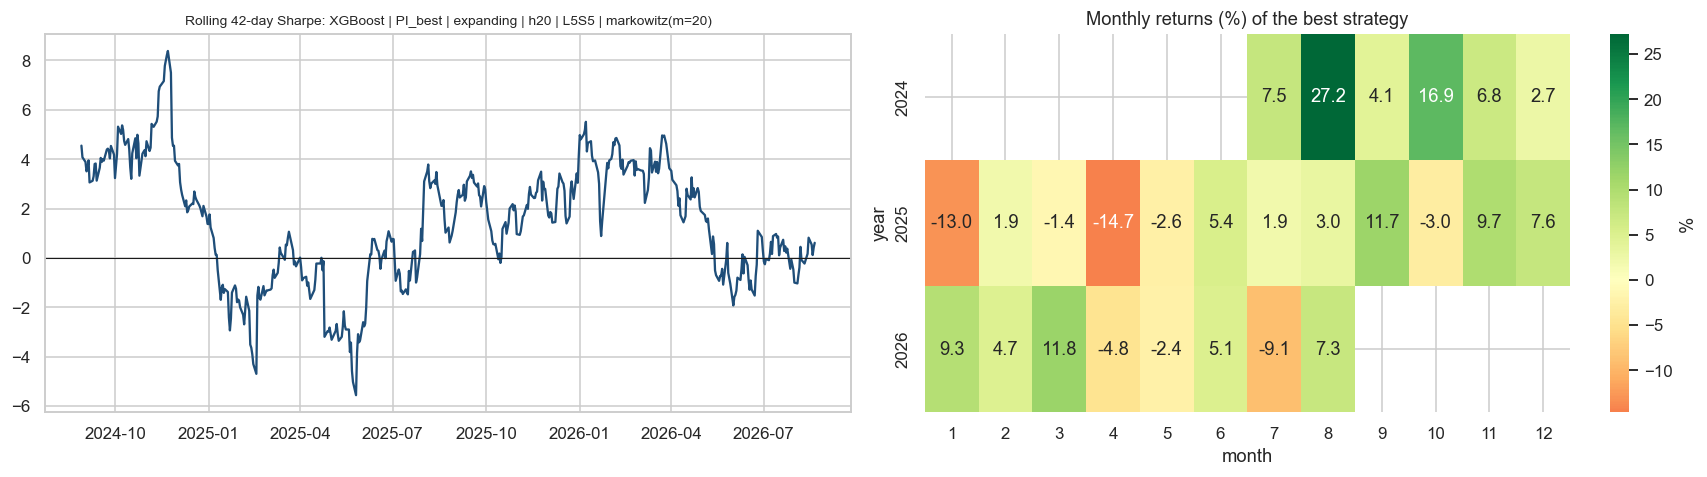

In [28]:
best = top5.iloc[0]
s = SERIES[best.strategy]
win = min(42, max(10, len(s) // 4))
roll = s["ret"].rolling(win).mean() / s["ret"].rolling(win).std() * np.sqrt(252)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(roll.index, roll, color="#1f4e79")
axes[0].axhline(0, color="k", lw=0.7)
axes[0].set_title(f"Rolling {win}-day Sharpe: {best.strategy}", fontsize=9)
monthly = s["ret"].groupby([s.index.year, s.index.month]).apply(lambda x: (1 + x).prod() - 1).unstack()
sns.heatmap(monthly * 100, annot=True, fmt=".1f", cmap="RdYlGn", center=0, ax=axes[1], cbar_kws={"label": "%"})
axes[1].set_title("Monthly returns (%) of the best strategy"); axes[1].set_xlabel("month"); axes[1].set_ylabel("year")
plt.tight_layout(); savefig("best_rolling_monthly"); plt.show()

### 11.5 Long vs short legs (best long–short strategy)

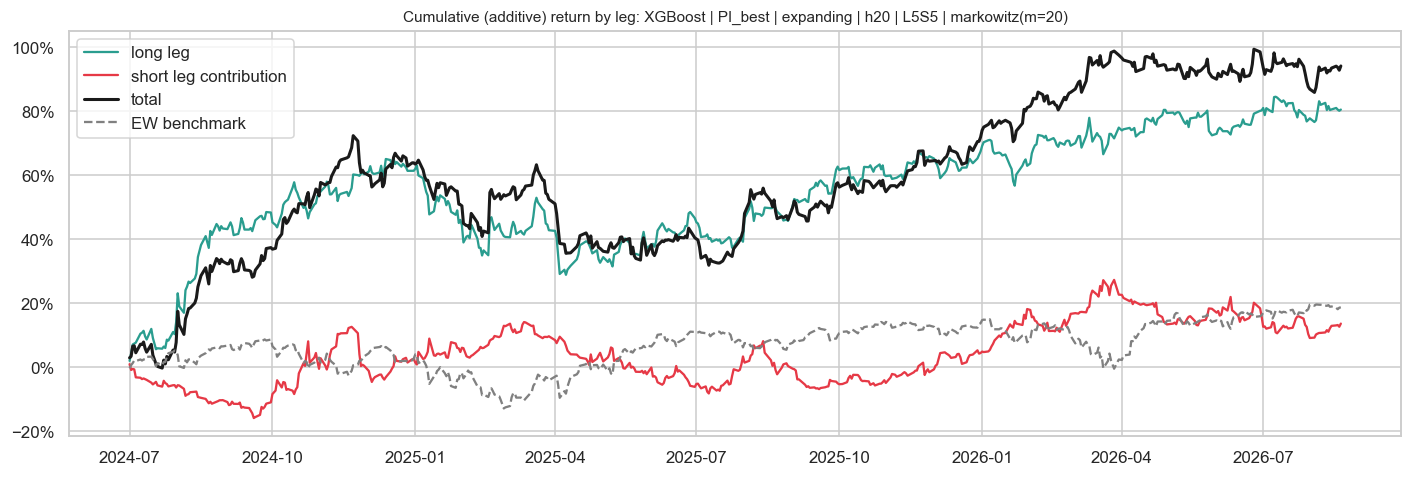

In [29]:
ls_best = RESULTS[RESULTS.portfolio.map(lambda p: PORTFOLIOS[p][1] > 0)].sort_values("sharpe", ascending=False)
if len(ls_best):
    r = ls_best.iloc[0]
    s = SERIES[r.strategy]
    fig, ax = plt.subplots(figsize=(13, 4.5))
    ax.plot(s.index, s["long"].cumsum(), label="long leg", color="#2a9d8f")
    ax.plot(s.index, s["short"].cumsum(), label="short leg contribution", color="#e63946")
    ax.plot(s.index, s["ret"].cumsum(), label="total", color="k", lw=2)
    ax.plot(BENCH.index, BENCH.cumsum(), label="EW benchmark", color="grey", ls="--")
    ax.set_title(f"Cumulative (additive) return by leg: {r.strategy}", fontsize=10)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.legend()
    plt.tight_layout(); savefig("long_short_legs"); plt.show()

### 11.6 Signal quality: IC through time, risk–return and turnover

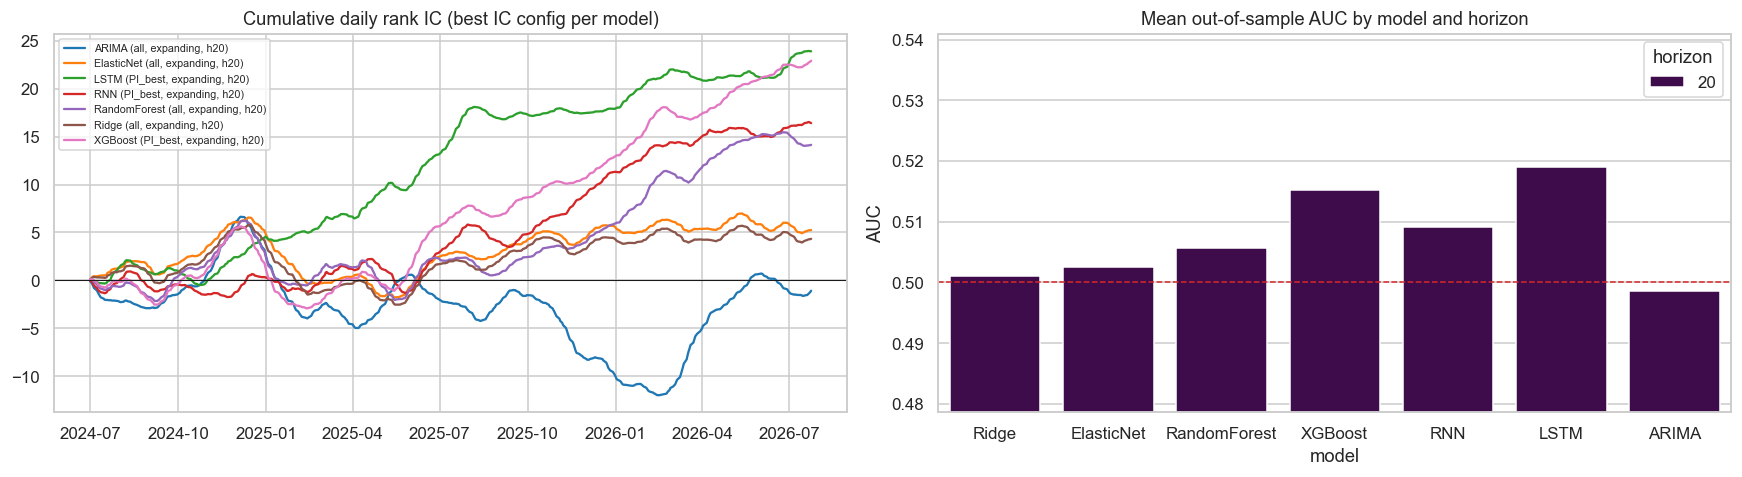

In [30]:
best_sig = RESULTS.groupby(["model", "fs", "train_method", "horizon"])["mean_IC"].first().reset_index()
best_sig = best_sig.loc[best_sig.groupby("model")["mean_IC"].idxmax()]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for c, (_, r) in zip(sns.color_palette("tab10", len(best_sig)), best_sig.iterrows()):
    ic = ICS[(r.model, r.fs, r.train_method, r.horizon)]
    axes[0].plot(ic.index, ic.cumsum(), color=c, label=f"{r.model} ({r.fs}, {r.train_method}, h{r.horizon})")
axes[0].axhline(0, color="k", lw=0.7)
axes[0].set_title("Cumulative daily rank IC (best IC config per model)"); axes[0].legend(fontsize=7)
sig_tab = RESULTS.drop_duplicates(["model", "fs", "train_method", "horizon"])
sns.barplot(data=sig_tab, x="model", y="AUC", hue="horizon", ax=axes[1], palette="viridis", errorbar=None)
axes[1].axhline(0.5, color="#d62828", ls="--", lw=1)
axes[1].set_ylim(max(0.4, sig_tab.AUC.min() - 0.02), min(0.65, sig_tab.AUC.max() + 0.02))
axes[1].set_title("Mean out-of-sample AUC by model and horizon")
plt.tight_layout(); savefig("signal_quality"); plt.show()

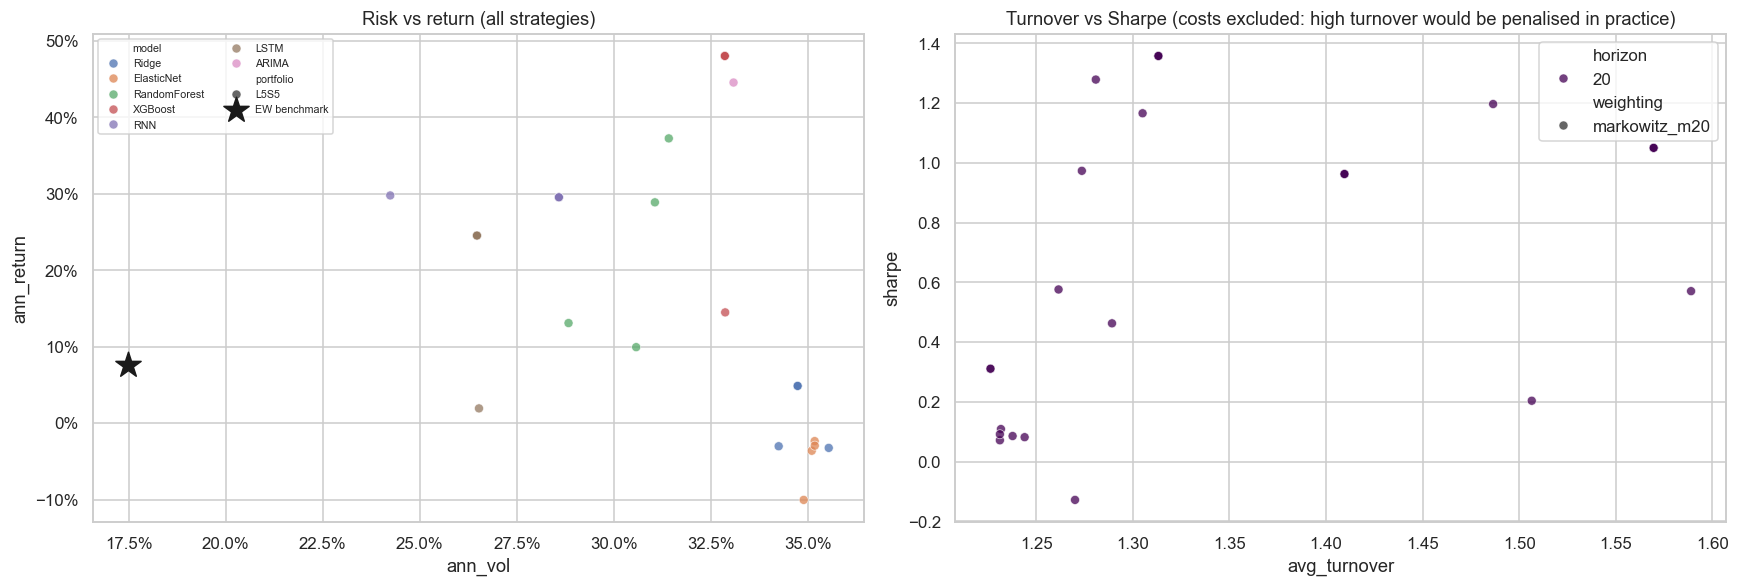

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.scatterplot(data=RESULTS, x="ann_vol", y="ann_return", hue="model", style="portfolio", ax=axes[0], s=35, alpha=0.75)
axes[0].scatter(bench_m["ann_vol"], bench_m["ann_return"], marker="*", s=300, color="k", label="EW benchmark")
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set_title("Risk vs return (all strategies)"); axes[0].legend(fontsize=7, ncol=2)
sns.scatterplot(data=RESULTS, x="avg_turnover", y="sharpe", hue="horizon", style="weighting", ax=axes[1], s=35,
                alpha=0.75, palette="viridis")
axes[1].set_title("Turnover vs Sharpe (costs excluded: high turnover would be penalised in practice)")
plt.tight_layout(); savefig("risk_return_turnover"); plt.show()

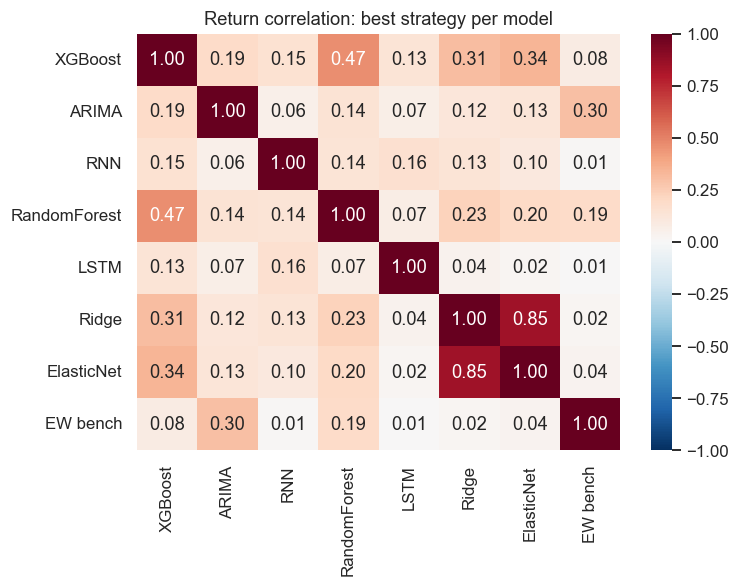

In [32]:
# correlation between the best strategies of each model (diversification potential)
rets = pd.DataFrame({r.model: SERIES[r.strategy]["ret"] for _, r in best_per_model.iterrows()})
rets["EW bench"] = BENCH
plt.figure(figsize=(7, 5.5))
sns.heatmap(rets.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Return correlation: best strategy per model")
plt.tight_layout(); savefig("strategy_correlation"); plt.show()

### 11.7 Feature selection vs using all features
Paper-style comparison: for each model, training method, horizon and portfolio, the Sharpe of each feature-selection method minus the Sharpe with **all** features.

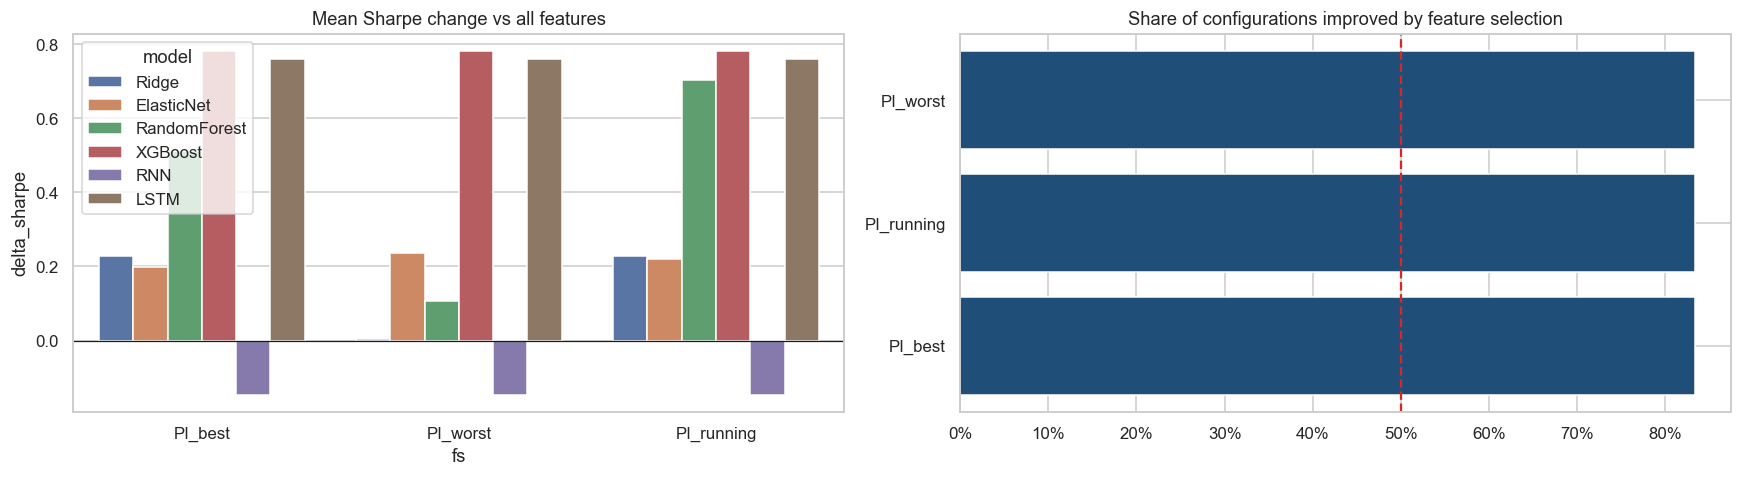

In [33]:
if "all" in FS_METHODS and len(FS_METHODS) > 1:
    keys = ["model", "train_method", "horizon", "portfolio", "weighting"]
    base = RESULTS[RESULTS.fs == "all"].set_index(keys)["sharpe"]
    d = RESULTS[RESULTS.fs != "all"].copy()
    d["delta_sharpe"] = d["sharpe"].values - base.reindex(d.set_index(keys).index).values
    d = d.dropna(subset=["delta_sharpe"])
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
    sns.barplot(data=d, x="fs", y="delta_sharpe", hue="model", ax=axes[0], errorbar=None)
    axes[0].axhline(0, color="k", lw=0.8)
    axes[0].set_title("Mean Sharpe change vs all features")
    share = d.groupby("fs")["delta_sharpe"].apply(lambda x: (x > 0).mean()).sort_values()
    axes[1].barh(share.index, share.values, color="#1f4e79")
    axes[1].axvline(0.5, color="#d62828", ls="--")
    axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    axes[1].set_title("Share of configurations improved by feature selection")
    plt.tight_layout(); savefig("fs_vs_all"); plt.show()

### 11.8 Summary tables

In [34]:
summary = {d: RESULTS.groupby(d).agg(mean_sharpe=("sharpe", "mean"), median_sharpe=("sharpe", "median"),
                                     best_sharpe=("sharpe", "max"), mean_IC=("mean_IC", "mean"),
                                     mean_max_dd=("max_dd", "mean")).round(3)
           for d in dims}
for d, t in summary.items():
    print(f"\n=== by {d} ===")
    display(t.sort_values("mean_sharpe", ascending=False))
if FAILED:
    print("\nFailed runs:")
    for f in FAILED:
        print(f)


=== by model ===


,mean_sharpe,median_sharpe,best_sharpe,mean_IC,mean_max_dd
model,,,,,
ARIMA,1.279,1.279,1.279,-0.002,-0.261
XGBoost,1.162,1.358,1.358,0.042,-0.381
RNN,1.087,1.050,1.197,0.032,-0.320
RandomForest,0.793,0.772,1.166,0.019,-0.271
LSTM,0.773,0.962,0.962,0.042,-0.304
Ridge,0.197,0.198,0.311,0.006,-0.393
ElasticNet,0.036,0.081,0.109,0.009,-0.452



=== by fs ===


,mean_sharpe,median_sharpe,best_sharpe,mean_IC,mean_max_dd
fs,,,,,
PI_running,0.823,1.006,1.358,0.026,-0.335
PI_best,0.787,0.968,1.358,0.027,-0.342
PI_worst,0.689,0.766,1.358,0.024,-0.339
all,0.524,0.463,1.279,0.019,-0.379



=== by train_method ===


...

,mean_sharpe,median_sharpe,best_sharpe,mean_IC,mean_max_dd
horizon,,,,,
20,0.699,0.962,1.358,0.024,-0.35



=== by portfolio ===


,mean_sharpe,median_sharpe,best_sharpe,mean_IC,mean_max_dd
portfolio,,,,,
L5S5,0.699,0.962,1.358,0.024,-0.35



=== by weighting ===


,mean_sharpe,median_sharpe,best_sharpe,mean_IC,mean_max_dd
weighting,,,,,
markowitz_m20,0.699,0.962,1.358,0.024,-0.35


Best strategy by sharpe: XGBoost | PI_best | expanding | h20 | L5S5 | markowitz(m=20)
Sharpe 1.36 | ann. return 48.03% | max DD -36.00% | mean IC 0.045

Portfolio on 2026-08-20 (entered at close, held until next rebalance)
Gross exposure 2.00 | net exposure 0.00
Next-day portfolio return: 1.331%


,date,symbol,side,P(win),rank,weight,close,past_20d_mean_ret,next_day_ret,contribution
0,2026-08-20,ITI IS Equity,LONG,0.562,1,+0.280,279.50,+0.040%,-0.09%,-0.025%
1,2026-08-20,JBMA IS Equity,LONG,0.557,2,+0.000,623.35,-0.270%,+8.12%,+0.000%
2,2026-08-20,VEDL IS Equity,LONG,0.552,3,+0.323,268.00,+0.076%,+4.10%,+1.327%
3,2026-08-20,CREDAG IS Equity,LONG,0.550,4,+0.379,"1,534.50",+0.113%,-2.50%,-0.948%
4,2026-08-20,KVB IS Equity,LONG,0.549,5,+0.018,334.10,-0.037%,+0.42%,+0.007%
5,2026-08-20,FSOL IS Equity,SHORT,0.386,238,-0.000,272.25,+0.421%,+1.40%,-0.000%
6,2026-08-20,TECHM IS Equity,SHORT,0.391,237,-0.052,"1,592.10",+0.122%,-0.51%,+0.026%
7,2026-08-20,ZENT IS Equity,SHORT,0.408,236,-0.148,484.95,-0.007%,-0.29%,+0.043%
8,2026-08-20,SUNP IS Equity,SHORT,0.415,235,-0.400,"1,904.00",-0.125%,-0.08%,+0.034%
9,2026-08-20,TRP IS Equity,SHORT,0.418,234,-0.400,"5,005.00",-0.047%,-2.17%,+0.867%


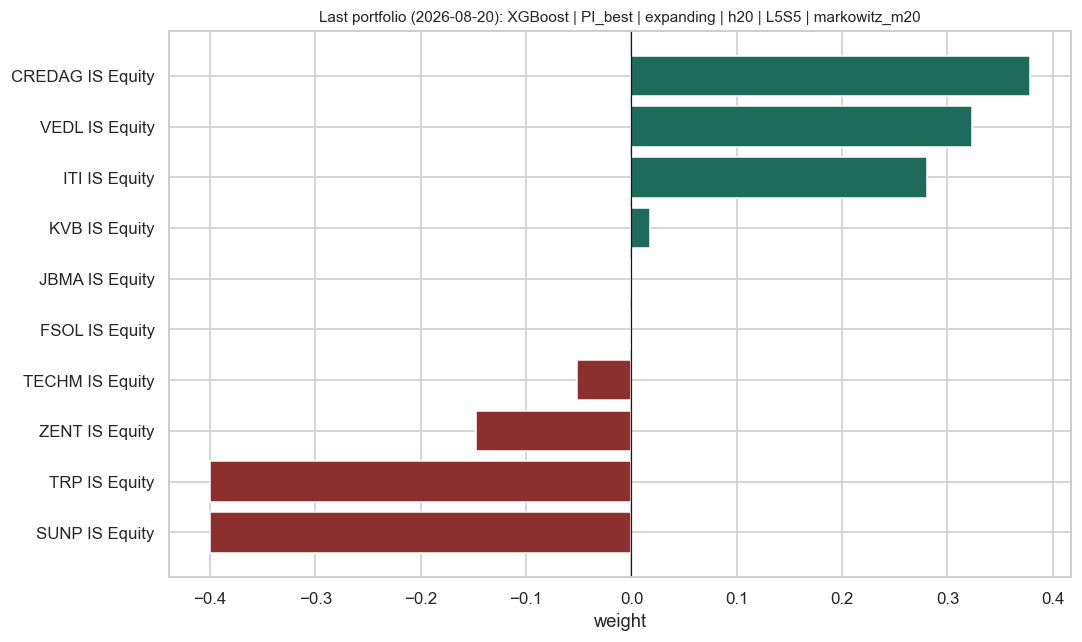

In [35]:
# ===================== Best model's last portfolio =====================
RANK_BY = "sharpe"          # metric used to pick the best strategy (e.g. "sharpe", "ann_return", "calmar")
N_LAST = 1                  # 1 = last rebalance only; e.g. 5 = last 5 rebalance days

best = RESULTS.sort_values(RANK_BY, ascending=False).iloc[0]
m, fs, tm, h = best.model, best.fs, best.train_method, int(best.horizon)
n_long, n_short = PORTFOLIOS[best.portfolio]
wgt = "equal" if best.weighting == "equal" else "markowitz"
mu_lb = None if wgt == "equal" else int(best.weighting.split("_m")[-1])

print(f"Best strategy by {RANK_BY}: {best.strategy}")
print(f"Sharpe {best.sharpe:.2f} | ann. return {best.ann_return:.2%} | max DD {best.max_dd:.2%} | mean IC {best.mean_IC:.3f}\n")

pred = generate_predictions(m, fs, tm, h)                       # cached, no retraining
P = np.full((N_DATES, N_SYMS), np.nan)
P[pred.dpos.values, pred.sid.values] = pred.prob.values

# rebalance days used by the backtest
reb = BT_POS if REBALANCE == "daily" else BT_POS[::h]
reb = [p for p in reb if np.isfinite(P[p]).sum() >= n_long + n_short]

def portfolio_on(p):
    probs = P[p]
    valid = np.where(np.isfinite(probs) & np.isfinite(CLOSE_W.values[p]))[0]
    order = valid[np.argsort(probs[valid], kind="stable")]
    L = order[-n_long:][::-1]
    S = order[:n_short] if n_short else np.array([], dtype=int)
    if wgt == "equal":
        wl = np.full(len(L), 1.0 / n_long)
        ws = np.full(len(S), -1.0 / n_short) if n_short else np.array([])
    else:
        ww = markowitz_weights(p, L, S, mu_lb)
        wl, ws = ww[:n_long], ww[n_long:]
    ids = np.r_[L, S].astype(int)
    lb = mu_lb or 20
    out = pd.DataFrame({
        "date": pd.Timestamp(DATES[p]).date(),
        "symbol": SYMS[ids],
        "side": ["LONG"] * len(L) + ["SHORT"] * len(S),
        "P(win)": probs[ids],
        "rank": [int((probs[valid] > probs[i]).sum()) + 1 for i in ids],
        "weight": np.r_[wl, ws],
        "close": CLOSE_W.values[p, ids],
        f"past_{lb}d_mean_ret": np.nanmean(RD[max(0, p - lb + 1):p + 1, ids], axis=0),
        "next_day_ret": RN[p, ids],
    })
    out["contribution"] = out["weight"] * out["next_day_ret"]
    return out

last_ports = pd.concat([portfolio_on(p) for p in reb[-N_LAST:]], ignore_index=True)
last = last_ports[last_ports.date == last_ports.date.max()]

print(f"Portfolio on {last.date.iloc[0]} (entered at close, held until next rebalance)")
print(f"Gross exposure {last.weight.abs().sum():.2f} | net exposure {last.weight.sum():.2f}")
if last.next_day_ret.notna().any():
    print(f"Next-day portfolio return: {last.contribution.sum():.3%}")
display(last.style.format({"P(win)": "{:.3f}", "weight": "{:+.3f}", "close": "{:,.2f}",
                           f"past_{mu_lb or 20}d_mean_ret": "{:+.3%}", "next_day_ret": "{:+.2%}",
                           "contribution": "{:+.3%}"})
                   .bar(subset=["weight"], align="mid", color=["#C0504D", "#4F81BD"]))

# chart of weights
fig, ax = plt.subplots(figsize=(10, 0.45 * len(last) + 1.5))
d = last.sort_values("weight")
ax.barh(d.symbol, d.weight, color=np.where(d.weight > 0, "#1E6B5C", "#8C2F2F"))
ax.axvline(0, color="k", lw=0.8)
ax.set_title(f"Last portfolio ({last.date.iloc[0]}): {m} | {fs} | {tm} | h{h} | {best.portfolio} | {best.weighting}", fontsize=10)
ax.set_xlabel("weight")
plt.tight_layout(); savefig("best_last_portfolio"); plt.show()

last_ports.to_csv(RESULTS_DIR / "best_last_portfolio.csv", index=False)

Testing: XGBoost | PI_best | expanding | h20 | L5S5 | markowitz(m=20)



Shuffled-label retrains:   0%|          | 0/10 [00:00<?, ?it/s]

,test,result,statistic,verdict
0,1. Random-ranking null,actual SR 1.93 vs null 95% = 1.17,p = 0.001,SIGNAL
1,2. Shuffled-label retrain,actual SR 1.93 vs shuffled max = 0.72,p = 0.00 (n=10),SIGNAL
2,3. IC block bootstrap,"mean IC 0.0447, 90% CI [0.0099, 0.0781]",P(IC>0) = 0.982,SIGNAL
3,4. Deflated Sharpe,"25 configs tested, SR threshold (ann.) 0.97",DSR = 0.715,consistent with NOISE


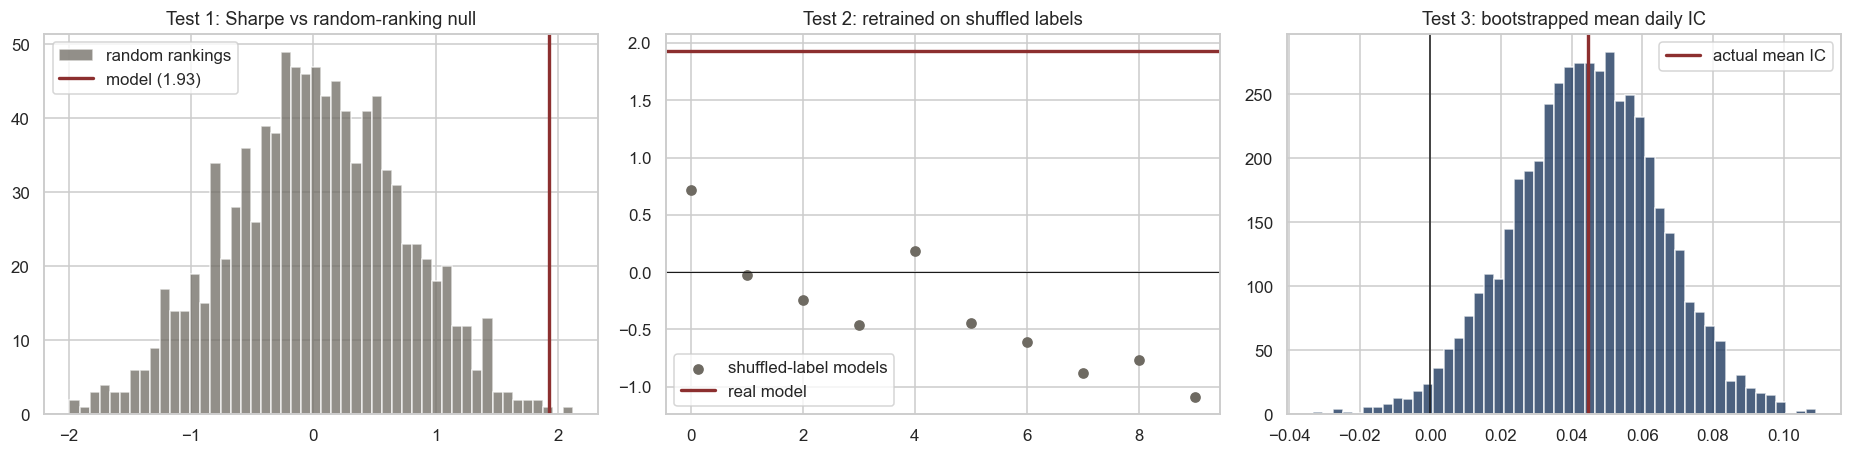

In [37]:
# ===================== Signal vs noise: bootstrap stress tests =====================
from scipy.stats import skew, kurtosis
N_NULL, N_LABEL, BLOCK, SEED_ST = 1000, 10, 20, 7     # N_LABEL = model retrains (slow part)
rng = np.random.default_rng(SEED_ST)

best = RESULTS.sort_values("sharpe", ascending=False).iloc[0]
m, fs, tm, h = best.model, best.fs, best.train_method, int(best.horizon)
nl, ns = PORTFOLIOS[best.portfolio]
pred = generate_predictions(m, fs, tm, h)
print(f"Testing: {best.strategy}\n")

def sharpe(x): x = np.asarray(x); return x.mean() / x.std() * np.sqrt(252) if x.std() > 0 else np.nan
# the ranking signal is tested with equal weights, so Markowitz sizing can't mask or create it
actual_eq = backtest(pred, nl, ns, "equal", None, h)["ret"].values
SR_ACT = sharpe(actual_eq)

# ---------- Test 1: random-ranking null (same universe, same days, same portfolio size)
P = np.full((N_DATES, N_SYMS), np.nan); P[pred.dpos.values, pred.sid.values] = pred.prob.values
null_rets = np.zeros((N_NULL, len(BT_POS)))
for k, p in enumerate(BT_POS):
    valid = np.where(np.isfinite(P[p]) & np.isfinite(CLOSE_W.values[p]))[0]
    if len(valid) < nl + ns:
        continue
    r = np.nan_to_num(RN[p, valid])
    sh = rng.permuted(np.tile(r, (N_NULL, 1)), axis=1)            # random ranking each sim
    null_rets[:, k] = sh[:, :nl].mean(1) - (sh[:, -ns:].mean(1) if ns else 0)
null_sr = null_rets.mean(1) / null_rets.std(1) * np.sqrt(252)
p1 = (null_sr >= SR_ACT).mean()

# ---------- Test 2: retrain on labels shuffled within each day (no learnable signal)
label_sr = []
if m != "ARIMA" and N_LABEL > 0:
    cols = FS_SELECTED[(m, fs, h)] if (m, fs, h) in FS_SELECTED else selected_features(m, fs, h)
    params, Y_orig, E_orig = BEST_PARAMS[(m, h)], Y[h].copy(), EXC[h].copy()
    by_date = np.argsort(DPOS, kind="stable")
    try:
        for s in tqdm(range(N_LABEL), desc="Shuffled-label retrains"):
            shuf = np.lexsort((rng.random(len(DPOS)), DPOS))           # random order within each date
            Y[h][by_date], EXC[h][by_date] = Y_orig[shuf], E_orig[shuf]
            parts = []
            for P0, end in refit_schedule(tm):
                a, b_ = train_range(P0, tm, h)
                tr, te = labeled(rows_between(a, b_), h), rows_between(P0, end)
                mdl = build_model(m, params).fit(tr, cols, h)
                parts.append(pd.DataFrame({"dpos": DPOS[te], "sid": SID[te], "prob": mdl.predict_proba(te, cols)}))
            label_sr.append(sharpe(backtest(pd.concat(parts), nl, ns, "equal", None, h)["ret"]))
    finally:
        Y[h][:], EXC[h][:] = Y_orig, E_orig                            # always restore real labels
    label_sr = np.array(label_sr)
p2 = (label_sr >= SR_ACT).mean() if len(label_sr) else np.nan

# ---------- Test 3: block bootstrap of the daily rank IC
ic = ICS[(m, fs, tm, h)].values
T = len(ic)
starts = rng.integers(0, T, size=(5000, int(np.ceil(T / BLOCK))))
idx = ((starts[:, :, None] + np.arange(BLOCK)) % T).reshape(5000, -1)[:, :T]
ic_boot = ic[idx].mean(1)
ic_lo, ic_hi = np.percentile(ic_boot, [5, 95])

# ---------- Test 4: deflated Sharpe ratio (corrects for choosing the best of many configs)
r = SERIES[best.strategy]["ret"].values
sr_d = r.mean() / r.std()                                        # daily, not annualised
trials = RESULTS["sharpe"].dropna().values / np.sqrt(252)
N_tr, V = len(trials), np.var(trials)
g = 0.5772156649
sr0 = np.sqrt(V) * ((1 - g) * norm.ppf(1 - 1 / N_tr) + g * norm.ppf(1 - 1 / (N_tr * np.e))) if N_tr > 1 else 0
dsr = norm.cdf((sr_d - sr0) * np.sqrt(len(r) - 1) /
               np.sqrt(1 - skew(r) * sr_d + (kurtosis(r, fisher=False) - 1) / 4 * sr_d ** 2))

# ---------- summary
verdict = lambda ok: "SIGNAL" if ok else "consistent with NOISE"
summary = pd.DataFrame([
    ["1. Random-ranking null", f"actual SR {SR_ACT:.2f} vs null 95% = {np.percentile(null_sr, 95):.2f}", f"p = {p1:.3f}", verdict(p1 < 0.05)],
    ["2. Shuffled-label retrain", (f"actual SR {SR_ACT:.2f} vs shuffled max = {label_sr.max():.2f}" if len(label_sr) else "skipped"),
     (f"p = {p2:.2f} (n={len(label_sr)})" if len(label_sr) else ""), verdict(len(label_sr) and p2 < 0.1)],
    ["3. IC block bootstrap", f"mean IC {ic.mean():.4f}, 90% CI [{ic_lo:.4f}, {ic_hi:.4f}]", f"P(IC>0) = {(ic_boot > 0).mean():.3f}", verdict(ic_lo > 0)],
    ["4. Deflated Sharpe", f"{N_tr} configs tested, SR threshold (ann.) {sr0 * np.sqrt(252):.2f}", f"DSR = {dsr:.3f}", verdict(dsr > 0.95)],
], columns=["test", "result", "statistic", "verdict"])
display(summary)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
axes[0].hist(null_sr, bins=50, color="#6E6A62", alpha=0.75, label="random rankings")
axes[0].axvline(SR_ACT, color="#8C2F2F", lw=2.2, label=f"model ({SR_ACT:.2f})")
axes[0].set_title("Test 1: Sharpe vs random-ranking null"); axes[0].legend()
if len(label_sr):
    axes[1].scatter(np.arange(len(label_sr)), label_sr, color="#6E6A62", label="shuffled-label models")
    axes[1].axhline(SR_ACT, color="#8C2F2F", lw=2.2, label="real model")
    axes[1].axhline(0, color="k", lw=0.7)
axes[1].set_title("Test 2: retrained on shuffled labels"); axes[1].legend()
axes[2].hist(ic_boot, bins=50, color="#1F3A5F", alpha=0.8)
axes[2].axvline(0, color="k", lw=1); axes[2].axvline(ic.mean(), color="#8C2F2F", lw=2.2, label="actual mean IC")
axes[2].set_title("Test 3: bootstrapped mean daily IC"); axes[2].legend()
plt.tight_layout(); savefig("signal_vs_noise"); plt.show()

In [ ]:
# ===================== Signal vs noise: bootstrap stress tests (Markowitz) =====================
from scipy.stats import skew, kurtosis
N_NULL, N_LABEL, BLOCK, SEED_ST = 200, 10, 20, 7     # Markowitz nulls are slower: 200 random paths
rng = np.random.default_rng(SEED_ST)

best = RESULTS.sort_values("sharpe", ascending=False).iloc[0]
m, fs, tm, h = best.model, best.fs, best.train_method, int(best.horizon)
nl, ns = PORTFOLIOS[best.portfolio]
WGT = "equal" if best.weighting == "equal" else "markowitz"
MU_LB = None if WGT == "equal" else int(best.weighting.split("_m")[-1])
pred = generate_predictions(m, fs, tm, h)
print(f"Testing: {best.strategy}\n")

def sharpe(x): x = np.asarray(x); return x.mean() / x.std() * np.sqrt(252) if x.std() > 0 else np.nan
actual = SERIES[best.strategy]["ret"].values            # the exact Markowitz series in the leaderboard
SR_ACT = sharpe(actual)

def weights(p, L, S):
    if WGT == "equal":
        return np.r_[np.full(nl, 1 / nl), np.full(ns, -1 / ns) if ns else []]
    return markowitz_weights(p, L, S, MU_LB)

# ---------- Test 1: random-ranking null, same Markowitz sizing, same days and portfolio size
P = np.full((N_DATES, N_SYMS), np.nan); P[pred.dpos.values, pred.sid.values] = pred.prob.values
null_rets = np.zeros((N_NULL, len(BT_POS)))
for k, p in enumerate(tqdm(BT_POS, desc="Random-ranking null")):
    valid = np.where(np.isfinite(P[p]) & np.isfinite(CLOSE_W.values[p]))[0]
    if len(valid) < nl + ns:
        continue
    r_next = np.nan_to_num(RN[p])
    for s in range(N_NULL):
        pick = rng.choice(valid, nl + ns, replace=False)              # random longs and shorts
        L, S = pick[:nl], pick[nl:]
        w = weights(p, L, S)
        null_rets[s, k] = w @ r_next[np.r_[L, S]]
null_sr = null_rets.mean(1) / null_rets.std(1) * np.sqrt(252)
p1 = (null_sr >= SR_ACT).mean()

# ---------- Test 2: retrain on labels shuffled within each day, same Markowitz backtest
label_sr = []
if m != "ARIMA" and N_LABEL > 0:
    cols = FS_SELECTED[(m, fs, h)] if (m, fs, h) in FS_SELECTED else selected_features(m, fs, h)
    params, Y_orig, E_orig = BEST_PARAMS[(m, h)], Y[h].copy(), EXC[h].copy()
    by_date = np.argsort(DPOS, kind="stable")
    try:
        for s in tqdm(range(N_LABEL), desc="Shuffled-label retrains"):
            shuf = np.lexsort((rng.random(len(DPOS)), DPOS))
            Y[h][by_date], EXC[h][by_date] = Y_orig[shuf], E_orig[shuf]
            parts = []
            for P0, end in refit_schedule(tm):
                a, b_ = train_range(P0, tm, h)
                tr, te = labeled(rows_between(a, b_), h), rows_between(P0, end)
                mdl = build_model(m, params).fit(tr, cols, h)
                parts.append(pd.DataFrame({"dpos": DPOS[te], "sid": SID[te], "prob": mdl.predict_proba(te, cols)}))
            label_sr.append(sharpe(backtest(pd.concat(parts), nl, ns, WGT, MU_LB, h)["ret"]))
    finally:
        Y[h][:], EXC[h][:] = Y_orig, E_orig
    label_sr = np.array(label_sr)
p2 = (label_sr >= SR_ACT).mean() if len(label_sr) else np.nan

# ---------- Test 3: block bootstrap of the daily rank IC (independent of weighting)
ic = ICS[(m, fs, tm, h)].values
T = len(ic)
starts = rng.integers(0, T, size=(5000, int(np.ceil(T / BLOCK))))
idx = ((starts[:, :, None] + np.arange(BLOCK)) % T).reshape(5000, -1)[:, :T]
ic_boot = ic[idx].mean(1)
ic_lo, ic_hi = np.percentile(ic_boot, [5, 95])

# ---------- Test 4: deflated Sharpe ratio
sr_d = actual.mean() / actual.std()
trials = RESULTS["sharpe"].dropna().values / np.sqrt(252)
N_tr, V = len(trials), np.var(trials)
g = 0.5772156649
sr0 = np.sqrt(V) * ((1 - g) * norm.ppf(1 - 1 / N_tr) + g * norm.ppf(1 - 1 / (N_tr * np.e))) if N_tr > 1 else 0
dsr = norm.cdf((sr_d - sr0) * np.sqrt(len(actual) - 1) /
               np.sqrt(1 - skew(actual) * sr_d + (kurtosis(actual, fisher=False) - 1) / 4 * sr_d ** 2))

# ---------- summary
verdict = lambda ok: "SIGNAL" if ok else "consistent with NOISE"
summary = pd.DataFrame([
    ["1. Random-ranking null", f"actual SR {SR_ACT:.2f} vs null 95% = {np.percentile(null_sr, 95):.2f}", f"p = {p1:.3f} (n={N_NULL})", verdict(p1 < 0.05)],
    ["2. Shuffled-label retrain", (f"actual SR {SR_ACT:.2f} vs shuffled max = {label_sr.max():.2f}" if len(label_sr) else "skipped"),
     (f"p = {p2:.2f} (n={len(label_sr)})" if len(label_sr) else ""), verdict(len(label_sr) and p2 < 0.1)],
    ["3. IC block bootstrap", f"mean IC {ic.mean():.4f}, 90% CI [{ic_lo:.4f}, {ic_hi:.4f}]", f"P(IC>0) = {(ic_boot > 0).mean():.3f}", verdict(ic_lo > 0)],
    ["4. Deflated Sharpe", f"{N_tr} configs tested, SR threshold (ann.) {sr0 * np.sqrt(252):.2f}", f"DSR = {dsr:.3f}", verdict(dsr > 0.95)],
], columns=["test", "result", "statistic", "verdict"])
display(summary)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
axes[0].hist(null_sr, bins=40, color="#6E6A62", alpha=0.75, label="random rankings (Markowitz)")
axes[0].axvline(SR_ACT, color="#8C2F2F", lw=2.2, label=f"model ({SR_ACT:.2f})")
axes[0].set_title("Test 1: Sharpe vs random-ranking null"); axes[0].legend()
if len(label_sr):
    axes[1].scatter(np.arange(len(label_sr)), label_sr, color="#6E6A62", label="shuffled-label models")
    axes[1].axhline(SR_ACT, color="#8C2F2F", lw=2.2, label=f"real model ({SR_ACT:.2f})")
    axes[1].axhline(0, color="k", lw=0.7)
axes[1].set_title("Test 2: retrained on shuffled labels"); axes[1].legend()
axes[2].hist(ic_boot, bins=50, color="#1F3A5F", alpha=0.8)
axes[2].axvline(0, color="k", lw=1); axes[2].axvline(ic.mean(), color="#8C2F2F", lw=2.2, label="actual mean IC")
axes[2].set_title("Test 3: bootstrapped mean daily IC"); axes[2].legend()
plt.tight_layout(); savefig("signal_vs_noise_markowitz"); plt.show()

Testing: XGBoost | PI_best | expanding | h20 | L5S5 | markowitz(m=20)



Random-ranking null:   0%|          | 0/532 [00:00<?, ?it/s]

## 12. Notes and caveats
* **No transaction costs**: daily rebalancing with high turnover would lose much of its edge after costs and shorting fees. Use `REBALANCE = "horizon"` to see a lower-turnover variant.
* **Test window**: about two years (Jul 2024 – Aug 2026). Sharpe estimates are still noisy; treat differences smaller than about 0.4 Sharpe as inconclusive.
* **Multiple testing**: many configurations are compared, so the best one is partly luck. Prefer settings that rank well across dimensions (Section 11.3) over a single top row.
* **Short selling on NSE**: overnight shorts in the cash market need SLB or derivatives; the long–short results are a research portfolio.
* **Survivorship**: if the stock list is today's constituents, all results (including the benchmark) are biased upwards.
* All outputs are saved in `RESULTS_DIR`: `leaderboard.csv`, `series.pkl`, and every figure in `figures/`.